<p style="text-align:center"><img src="../images/04_10_spatial_capstone.png" alt="Spatial Statistics Capstone" width="100%"></p>


# Spatial Patterns, Socioeconomic Determinants, and Geographic Inequalities in Health Outcomes Across U.S. Counties

This is Part 10 (Capstone) of the spatial-statistics module. It follows the course guideline *Health Disparities.qmd* step by step: where county health outcomes cluster, how they relate to economic deprivation and social vulnerability, whether those associations vary geographically, how the pattern holds across release years, and which counties face overlapping disadvantages.

All county indicators come from the local **USA Health Data Atlas SQLite database** (`Data/00_shared/data_spatial_stat/usa_health_atlas_database/`): County Health Rankings (CHR), CDC/ATSDR Social Vulnerability Index (SVI), and Census PEP demography. Geometry is `US_COUNTY.shp` (CONUS counties, NAD83 Albers).

Following the guideline's recommended starting point, the notebook concentrates on **diabetes prevalence**, **adult obesity**, and **premature death** (YPLL), explained by an **Economic Deprivation Index (EDI)**, overall **SVI**, **healthcare access**, and **PM2.5**.

## Overview

> Across contiguous-U.S. counties, are diabetes, obesity, and premature death spatially clustered? Are economically deprived and socially vulnerable counties more likely to carry higher disease burden? Do socioeconomic associations vary geographically, and which counties combine multiple forms of disadvantage?

### Research questions

| Research question | Statistical approach | Guideline section |
|---|---|---|
| Where are health outcomes highest and lowest? | Choropleth and bivariate choropleth mapping | 5 |
| Are health outcomes spatially clustered? | Global Moran's I (Queen and KNN weights) | 6 |
| Where are significant high- and low-risk clusters? | Local Moran's I (LISA) with FDR, Gi* | 7 |
| Do deprived counties sit among high-burden neighbors? | Bivariate Moran's I and bivariate LISA | 8 |
| Are health disparities associated with socioeconomic deprivation? | OLS with diagnostics and LM tests | 9A |
| Are neighboring counties influencing health outcomes? | Spatial lag, spatial error, spatial Durbin; direct and indirect impacts | 9B |
| Do socioeconomic effects vary geographically? | GWR (CONUS) and MGWR (Deep South) | 9C |
| Which factors matter most, and are effects nonlinear? | XGBoost + TreeSHAP with state-grouped CV | 10 |
| How do health disparities change over time? | CHR 2022-2025 panel: yearly Moran's I, hot-spot persistence, two-way fixed effects | 11 |
| Which counties face overlapping disadvantages? | Health Disparity Index (HDI) with weighting checks | 12 |

### Outcomes and predictors (Atlas release year)

| Role | Variable | Atlas source |
|---|---|---|
| Outcome | `diabetes` | CHR 2024 `Diabetes Prevalence` (proportion) |
| Outcome | `obesity` | CHR 2024 `Adult Obesity` |
| Outcome | `premature_death` | CHR 2024 `Premature Death` (YPLL rate) |
| Deprivation | `edi` | Mean of SVI 2022 `EPL_POV150`, `EPL_UNEMP`, `EPL_NOHSDP`, `EPL_NOVEH`, `EPL_HBURD` |
| Vulnerability | `svi` | SVI 2022 `RPL_THEMES` |
| Access | `uninsured` | CHR 2024 `Uninsured` |
| Access | `pcp` | CHR 2024 `Primary Care Physicians` (rate) |
| Environment | `pm25` | CHR 2024 `Air Pollution: Particulate Matter` |
| Context | `pct_rural` | Census PEP `PCT_RURAL` (2022) |
| Behavior (ESDA) | `inactivity`, `smoking` | CHR 2024 physical inactivity and adult smoking |
| Panel | `diabetes`, `uninsured`, `children_poverty`, `unemployment` | CHR releases 2022 to 2025 |

EDI uses SVI percentile ranks that already point in the same direction (higher = more deprived). Those five EPL components are **not** entered again as separate regressors alongside `edi`.

| Step | What we do |
|------|------------|
| Data | SQL extract from the Atlas SQLite DB; coverage audit; FIPS join to `US_COUNTY.shp`; CRS audit |
| Indicators | Build EDI (equal-weighted, checked against PCA) and a descriptive Health Disparity Index (HDI) |
| ESDA | Choropleths, bivariate choropleth, scatterplots, histograms |
| Autocorrelation | Global Moran's I for outcomes and EDI; Moran scatter; KNN sensitivity |
| Local clusters | LISA (uncorrected and FDR) and Gi* for diabetes |
| Bivariate | Bivariate Moran and bivariate LISA (EDI vs diabetes) |
| Modeling | OLS, LM tests, spatial lag, spatial error, spatial Durbin; impacts; residual Moran; VIF |
| Heterogeneity | GWR local slopes for EDI on diabetes; MGWR covariate-specific bandwidths in the Deep South |
| GeoAI | XGBoost with state-grouped CV and TreeSHAP (`pred_contribs`) |
| Multi-year | CHR 2022-2025 panel: Moran's I by release, hot-spot persistence, two-way fixed effects |
| Priority map | HDI choropleth of overlapping disadvantages; ranking stability under other weights |
| Report | Decision log and caveats |

**Caveats.** County associations are ecological, not individual causal effects. CHR measures are model-based estimates with their own uncertainty. The cross-sectional sections use one release (CHR 2024 + SVI 2022). The multi-year section uses CHR releases, which are not calendar years and can reuse or re-model the underlying data, so it is read as a stability check and not as an annual trend. Every number below is computed in this notebook.

## API overview

```
- sqlite3 -> USA Health Data Atlas database
- SpatialData, Queen, W, KNN
- Moran, MoranBV, Moran_Local_BV, moran_scatter
- local_moran_clusters, getis_ord_gi
- OLS (lm_tests, breusch_pagan, jarque_bera), SpatialLag, SpatialError, SpatialDurbin, lr_test, compare_models
- GWR; mgwr (PySAL): Sel_BW, MGWR
- xgboost.XGBRegressor (TreeSHAP via pred_contribs), sklearn GroupKFold
- geopandas / matplotlib / apply_map_style
```

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README. It also uses `statsmodels`, which no GeoLattice option installs: `pip install statsmodels`.

In [1]:
import sys
import warnings
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch
from IPython.display import Markdown, display
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
import xgboost as xgb
from sklearn.model_selection import GroupKFold

ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "pyproject.toml").is_file() and (candidate / "Data").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not find the GeoLattice repository root.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "Data" / "00_shared" / "data_spatial_stat"
DB = DATA / "usa_health_atlas_database" / "usa_health_atlas.sqlite"
SHP = DATA / "US_COUNTY.shp"

import geolattice.spatial_statistics
from geolattice.viz import apply_map_style
from geolattice.spatial_statistics.core import SpatialData
from geolattice.spatial_statistics.weights import Queen, W, KNN
from geolattice.spatial_statistics.esda import Moran, MoranBV, Moran_Local_BV
from geolattice.spatial_statistics.viz import moran_scatter
from geolattice.spatial_statistics.cluster import local_moran_clusters, getis_ord_gi
from geolattice.spatial_statistics.regression import (
    OLS, SpatialLag, SpatialError, SpatialDurbin, lr_test, compare_models,
)
from geolattice.spatial_statistics.gwmodel.linear import GWR

apply_map_style()

SEED = 7
PERM = 999
PERM_LOCAL = 9999  # finer p-value grid for FDR-corrected local statistics
ALPHA = 0.05
CHR_YEAR = 2024
SVI_YEAR = 2022
CENSUS_YEAR = 2022
PANEL_YEARS = [2022, 2023, 2024, 2025]  # CHR releases with a consistent diabetes series (Section 11)
MGWR_STATES = ["Georgia", "Mississippi", "Louisiana", "Alabama", "South Carolina"]

OUTCOMES = {
    "diabetes": "Diabetes prevalence",
    "obesity": "Adult obesity",
    "premature_death": "Premature death (YPLL)",
}
PREDICTORS = ["edi", "svi", "uninsured", "pcp", "pm25", "pct_rural"]
PRED_LABELS = {
    "edi": "Economic deprivation (EDI)",
    "svi": "SVI overall",
    "uninsured": "% uninsured",
    "pcp": "Primary care physicians",
    "pm25": "PM2.5",
    "pct_rural": "% rural",
}
EDI_COMPONENTS = ["EPL_POV150", "EPL_UNEMP", "EPL_NOHSDP", "EPL_NOVEH", "EPL_HBURD"]

print(f"geolattice.spatial_statistics : version {geolattice.spatial_statistics.__version__}")
print(f"database : {DB.relative_to(ROOT)}  ({DB.stat().st_size / 1e6:.0f} MB)")
print(f"seed {SEED}  |  permutations {PERM} (global), {PERM_LOCAL} (local FDR)  |  alpha {ALPHA}")
print(f"CHR {CHR_YEAR}  |  SVI {SVI_YEAR}  |  Census rural {CENSUS_YEAR}  |  panel {PANEL_YEARS[0]}-{PANEL_YEARS[-1]}")


geolattice.spatial_statistics : version 0.3.49
database : Data/00_shared/data_spatial_stat/usa_health_atlas_database/usa_health_atlas.sqlite  (162 MB)
seed 7  |  permutations 999 (global), 9999 (local FDR)  |  alpha 0.05
CHR 2024  |  SVI 2022  |  Census rural 2022  |  panel 2022-2025


## Data: the USA Health Data Atlas database

Module 1 of the guideline is data integration. The Atlas SQLite database already holds CHR, SVI, and Census PEP as long `county_indicators` rows. We first audit which dataset-years are available, then pivot the needed variables to a county-level analysis table and join CONUS polygons on five-digit FIPS. The guideline warns that sources do not share a reference year, so the year of each input is kept explicit in `SPEC`.

In [2]:
con = sqlite3.connect(DB)
tables = pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", con
)
catalog = pd.read_sql(
    "SELECT dataset_id, dataset_name, temporal_coverage, notes FROM dataset_catalog",
    con,
)
load_log = pd.read_sql(
    "SELECT dataset_name, rows_loaded, status FROM data_load_log ORDER BY load_id",
    con,
)
coverage = pd.read_sql(
    "SELECT d.dataset_name, i.year, COUNT(DISTINCT i.variable) AS variables, "
    "COUNT(DISTINCT i.fips) AS counties "
    "FROM county_indicators AS i JOIN dataset_catalog AS d USING (dataset_id) "
    "GROUP BY d.dataset_name, i.year ORDER BY d.dataset_name, i.year",
    con,
)
display(tables.T)
display(catalog)
display(load_log)
display(Markdown("**Dataset-year coverage (counties with at least one value)**"))
display(coverage.pivot(index="dataset_name", columns="year", values="counties").fillna(0).astype(int))

# Spec: analysis_name -> (dataset_name, variable, year)
SPEC = {
    "diabetes": ("county_health_rankings", "Diabetes Prevalence", CHR_YEAR),
    "obesity": ("county_health_rankings", "Adult Obesity", CHR_YEAR),
    "premature_death": ("county_health_rankings", "Premature Death", CHR_YEAR),
    "uninsured": ("county_health_rankings", "Uninsured", CHR_YEAR),
    "pcp": ("county_health_rankings", "Primary Care Physicians", CHR_YEAR),
    "pm25": ("county_health_rankings", "Air Pollution: Particulate Matter", CHR_YEAR),
    "inactivity": ("county_health_rankings", "Physical Inactivity", CHR_YEAR),
    "smoking": ("county_health_rankings", "Adult Smoking", CHR_YEAR),
    "children_poverty": ("county_health_rankings", "Children in Poverty", CHR_YEAR),
    "unemployment_chr": ("county_health_rankings", "Unemployment", CHR_YEAR),
    "some_college": ("county_health_rankings", "Some College", CHR_YEAR),
    "svi": ("social_vulnerability_index", "RPL_THEMES", SVI_YEAR),
    "pct_rural": ("census_demography", "PCT_RURAL", CENSUS_YEAR),
    "pop": ("census_demography", "POP", CENSUS_YEAR),
}
for comp in EDI_COMPONENTS:
    SPEC[comp.lower()] = ("social_vulnerability_index", comp, SVI_YEAR)

params = []
for dataset, variable, year in SPEC.values():
    params.extend([dataset, variable, year])
placeholders = ",".join(["(?, ?, ?)"] * len(SPEC))
indicator_sql = (
    "SELECT i.fips, d.dataset_name, i.variable, i.year, i.value "
    "FROM county_indicators AS i "
    "JOIN dataset_catalog AS d USING (dataset_id) "
    "WHERE (d.dataset_name, i.variable, i.year) IN (" + placeholders + ")"
)
long = pd.read_sql(indicator_sql, con, params=params)
con.close()

wide = long.pivot_table(
    index="fips", columns=["dataset_name", "variable", "year"], values="value"
)
table = pd.DataFrame(index=wide.index.astype(str).str.zfill(5))
for name, (dataset, variable, year) in SPEC.items():
    table[name] = wide[(dataset, variable, year)].to_numpy()

# EDI: equal-weighted mean of aligned SVI percentiles (already 0-1, higher = worse)
edi_cols = [c.lower() for c in EDI_COMPONENTS]
table["edi"] = table[edi_cols].mean(axis=1)

# Scale prevalence outcomes to percent for readable maps/tables
table["diabetes_pct"] = 100 * table["diabetes"]
table["obesity_pct"] = 100 * table["obesity"]

display(table[["diabetes_pct", "obesity_pct", "premature_death", "edi", "svi", "uninsured", "pcp", "pm25", "pct_rural"]].describe().round(3))
display(Markdown(
    f"Extracted **{len(table):,}** county rows. "
    f"Mean diabetes prevalence is **{table['diabetes_pct'].mean():.1f}%**; "
    f"mean EDI is **{table['edi'].mean():.3f}** (SVI percentile scale)."
))


,0,1,2,3,4,5,6,7
name,counties,county_indicators,data_load_log,dataset_catalog,presidential_election_results,source_records,sqlite_stat1,sqlite_stat4


,dataset_id,dataset_name,temporal_coverage,notes
0,1,county_health_rankings,2020–2025,"Measures, ranks and outcomes; selected year in..."
1,2,social_vulnerability_index,2022,County-level SVI percentile ranks.
2,3,health_experience_places,Current release,Crude prevalence estimates for health outcomes...
3,4,mortality,2019–2023,"Age-adjusted mortality rates per 100,000."
4,5,census_demography,2010–2023,"Population, population change, births, deaths,..."
5,6,religion_census,"2010, 2020","Adherents, congregations, rates and population..."
6,7,presidential_election,"2004, 2008, 2012, 2016, 2020, 2024",County presidential returns; 2024 source is co...
7,8,cancer_incidence,2020–2025; pooled 2017–2021,Synthetic annual incidence and observed pooled...
8,9,cancer_mortality,2019–2023,Reconstructed county cancer mortality.
9,10,overdose_mortality,"2003 onward, depending on layer","Model-based, provisional, and opioid mortality..."


,dataset_name,rows_loaded,status
0,presidential_election,18929,success
1,census_demography,871839,success
2,social_vulnerability_index,66024,success
3,religion_census,116852,success
4,county_health_rankings,569997,success


**Dataset-year coverage (counties with at least one value)**

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
dataset_name,,,,,,,,,,,,,,,,
census_demography,3225,3225,3225,3225,3225,3225,3225,3225,3225,3225,3234,3234,3234,3234,0,0
county_health_rankings,0,0,0,0,0,0,0,0,0,0,3141,3141,3141,3141,3143,3152
religion_census,3109,0,0,0,0,0,0,0,0,0,3142,0,0,0,0,0
social_vulnerability_index,0,0,0,0,0,0,0,0,0,0,0,0,3144,0,0,0


,diabetes_pct,obesity_pct,premature_death,edi,svi,uninsured,pcp,pm25,pct_rural
count,3143.000,3143.000,3088.000,3144.000,3144.000,3142.000,2986.000,3115.000,3221.000
mean,10.571,37.352,9850.746,0.496,0.500,0.115,0.001,7.536,57.525
std,2.250,4.559,3482.689,0.207,0.289,0.053,0.000,1.712,32.040
min,5.600,17.400,2418.325,0.013,0.000,0.024,0.000,0.900,0.000
25%,8.900,35.100,7435.596,0.335,0.250,0.075,0.000,6.500,31.590
50%,10.200,37.700,9377.864,0.498,0.500,0.104,0.000,7.800,58.610
75%,11.800,40.300,11708.594,0.647,0.750,0.146,0.001,8.800,85.900
max,22.200,52.500,41152.261,0.988,1.000,0.463,0.006,15.600,100.000


Extracted **3,234** county rows. Mean diabetes prevalence is **10.6%**; mean EDI is **0.496** (SVI percentile scale).

## Spatial join and complete-case study region

Join attributes to `US_COUNTY.shp` on FIPS. Keep complete cases for the modeling covariates and primary outcome (diabetes). Projected CRS is NAD83 Albers (metres), suitable for contiguity weights and GWR coordinates.


In [3]:
shp = gpd.read_file(SHP)
shp["fips"] = shp["FIPS"].astype(int).astype(str).str.zfill(5)
merged = shp.merge(table.reset_index().rename(columns={"index": "fips"}), on="fips", how="inner")

need = ["diabetes", "obesity", "premature_death", "edi", "svi", "uninsured", "pcp", "pm25", "pct_rural"]
before = len(merged)
counties = merged.dropna(subset=need).copy().reset_index(drop=True)
print("CRS:", counties.crs)
print(f"joined {before:,} -> complete-case {len(counties):,} counties")
print(counties[["STATE"]].value_counts().head())
lost = merged.loc[merged[need].isna().any(axis=1), "STATE"].value_counts()
print("counties dropped for missing inputs, top states:", lost.head(5).to_dict())
print("missing by variable:", merged[need].isna().sum()[lambda s: s > 0].to_dict())

# Centroids in projected metres for KNN / GWR
coords = np.column_stack([counties.geometry.centroid.x, counties.geometry.centroid.y])
counties["x"] = coords[:, 0]
counties["y"] = coords[:, 1]

study = SpatialData(counties, y="diabetes_pct", X=PREDICTORS)
display(Markdown(
    f"Study region: **{len(counties):,}** CONUS counties with complete diabetes predictors "
    f"in {counties.crs.to_string() if counties.crs else 'unknown CRS'}."
))
display(counties[["fips", "COUNTY", "STATE", "diabetes_pct", "obesity_pct", "edi", "svi", "pm25"]].head())


CRS: PROJCS["NAD_1983_Albers",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",23],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
joined 3,108 -> complete-case 2,897 counties
STATE   
Texas       221
Georgia     146
Virginia    125
Kentucky    112
Missouri    111
Name: count, dtype: int64
counties dropped for missing inputs, top states: {'Texas': 33, 'Nebraska': 21, 'North Dakota': 17, 'South Dakota': 15, 'Georgia': 13}
missing by variable: {'diabetes': 1, 'obesity': 1, 'premature_death': 49, 'edi': 9, 'svi': 9, 'uninsured': 1, 'pcp': 155, 'pm25': 1}


Study region: **2,897** CONUS counties with complete diabetes predictors in PROJCS["NAD_1983_Albers",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",23],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]].

,fips,COUNTY,STATE,diabetes_pct,obesity_pct,edi,svi,pm25
0,01059,Franklin County,Alabama,12.6,39.1,0.62208,0.7576,8.2
1,13111,Fannin County,Georgia,10.4,32.9,0.59720,0.6172,7.9
2,19109,Kossuth County,Iowa,8.8,39.1,0.33764,0.2030,6.9
3,40115,Ottawa County,Oklahoma,13.3,41.5,0.61032,0.9252,8.3
4,42115,Susquehanna County,Pennsylvania,8.9,41.1,0.47452,0.1814,6.6


## Indicator construction: EDI and Health Disparity Index

EDI is the equal-weighted mean of five SVI deprivation percentiles. HDI is a descriptive composite of standardized diabetes, obesity, premature death, EDI, SVI, uninsured, and PM2.5 (PCP enters inverted so that higher HDI = worse). HDI is for ranking and mapping, not a validated needs score.


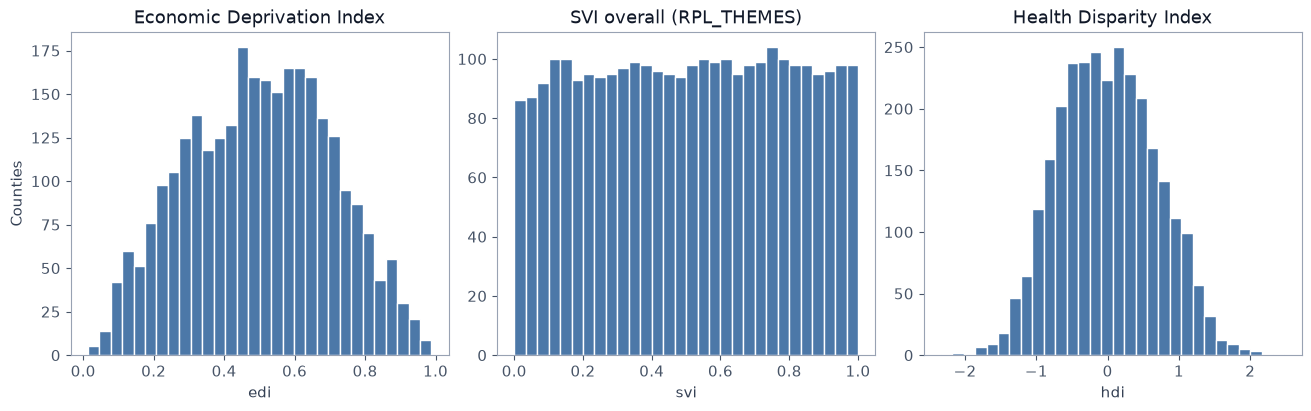

,edi,svi,hdi
count,2897.000,2897.000,2897.000
mean,0.501,0.506,-0.000
std,0.204,0.287,0.685
min,0.013,0.000,-2.341
25%,0.340,0.259,-0.515
50%,0.505,0.510,-0.016
75%,0.650,0.753,0.487
max,0.988,1.000,2.480


EDI uses **5** SVI components. HDI mean is **-0.000** (SD **0.685**).

In [4]:
def zscore(s: pd.Series) -> pd.Series:
    return (s - s.mean()) / s.std(ddof=0)


hdi_parts = pd.DataFrame(
    {
        "z_diabetes": zscore(counties["diabetes"]),
        "z_obesity": zscore(counties["obesity"]),
        "z_premature": zscore(counties["premature_death"]),
        "z_edi": zscore(counties["edi"]),
        "z_svi": zscore(counties["svi"]),
        "z_uninsured": zscore(counties["uninsured"]),
        "z_pm25": zscore(counties["pm25"]),
        "z_low_pcp": zscore(-counties["pcp"]),  # fewer physicians -> higher disparity
    }
)
counties["hdi"] = hdi_parts.mean(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, col, title, bins in [
    (axes[0], "edi", "Economic Deprivation Index", 30),
    (axes[1], "svi", "SVI overall (RPL_THEMES)", 30),
    (axes[2], "hdi", "Health Disparity Index", 30),
]:
    ax.hist(counties[col], bins=bins, color="#4C78A8", edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel(col)
axes[0].set_ylabel("Counties")
plt.show()

display(counties[["edi", "svi", "hdi"]].describe().round(3))
display(Markdown(
    f"EDI uses **{len(EDI_COMPONENTS)}** SVI components. "
    f"HDI mean is **{counties['hdi'].mean():.3f}** (SD **{counties['hdi'].std():.3f}**)."
))


### EDI check: equal weights versus PCA

The guideline suggests comparing the equal-weighted index with a PCA-based one. The first principal component of the five standardized SVI components is a data-driven weighting. If the two indices rank counties almost identically, the simpler equal-weighted EDI is kept for the models.

,PC1 loading,equal weight
EPL_POV150,0.531,0.447
EPL_UNEMP,0.461,0.447
EPL_NOHSDP,0.449,0.447
EPL_NOVEH,0.443,0.447
EPL_HBURD,0.328,0.447


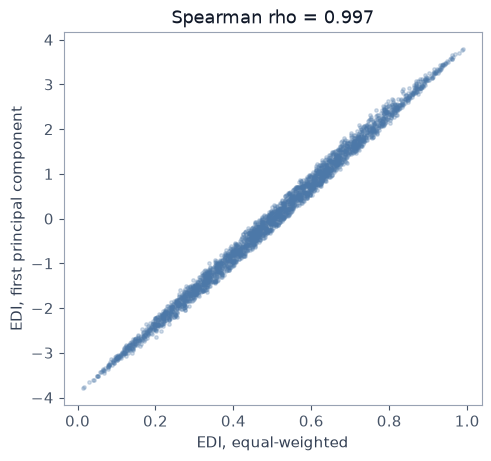

PC1 explains **52%** of the variance of the five components. Spearman correlation between the two indices is **0.997**, and **96%** of the counties in the top equal-weighted quintile are also in the top PCA quintile. The lowest PC1 loading is **EPL_HBURD** (0.33); the equal-weighted EDI is used below.

In [5]:
E = counties[edi_cols].to_numpy(float)
Ez = (E - E.mean(axis=0)) / E.std(axis=0, ddof=0)
_, sing, Vt = np.linalg.svd(Ez, full_matrices=False)
explained = sing ** 2 / np.sum(sing ** 2)
loadings = Vt[0] * np.sign(Vt[0].sum())  # orient so that higher = more deprived
counties["edi_pca"] = Ez @ loadings

load_tbl = pd.DataFrame(
    {"PC1 loading": loadings, "equal weight": 1 / np.sqrt(len(edi_cols))},
    index=EDI_COMPONENTS,
)
display(load_tbl.style.format("{:.3f}"))

rho_edi = spearmanr(counties["edi"], counties["edi_pca"])[0]
top_eq = set(counties.index[counties["edi"] >= counties["edi"].quantile(0.8)])
top_pc = set(counties.index[counties["edi_pca"] >= counties["edi_pca"].quantile(0.8)])
share_top = len(top_eq & top_pc) / len(top_eq)

fig, ax = plt.subplots(figsize=(4.8, 4.5), constrained_layout=True)
ax.scatter(counties["edi"], counties["edi_pca"], s=6, alpha=0.25, color="#4C78A8")
ax.set_xlabel("EDI, equal-weighted")
ax.set_ylabel("EDI, first principal component")
ax.set_title(f"Spearman rho = {rho_edi:.3f}")
plt.show()

display(Markdown(
    f"PC1 explains **{explained[0] * 100:.0f}%** of the variance of the five components. "
    f"Spearman correlation between the two indices is **{rho_edi:.3f}**, and "
    f"**{share_top * 100:.0f}%** of the counties in the top equal-weighted quintile are also in the top PCA quintile. "
    f"The lowest PC1 loading is **{load_tbl['PC1 loading'].idxmin()}** "
    f"({load_tbl['PC1 loading'].min():.2f}); the equal-weighted EDI is used below."
))

## Exploratory maps and relationships

Choropleths of the three health outcomes, EDI, SVI, and HDI, plus scatterplots of diabetes against deprivation and access.


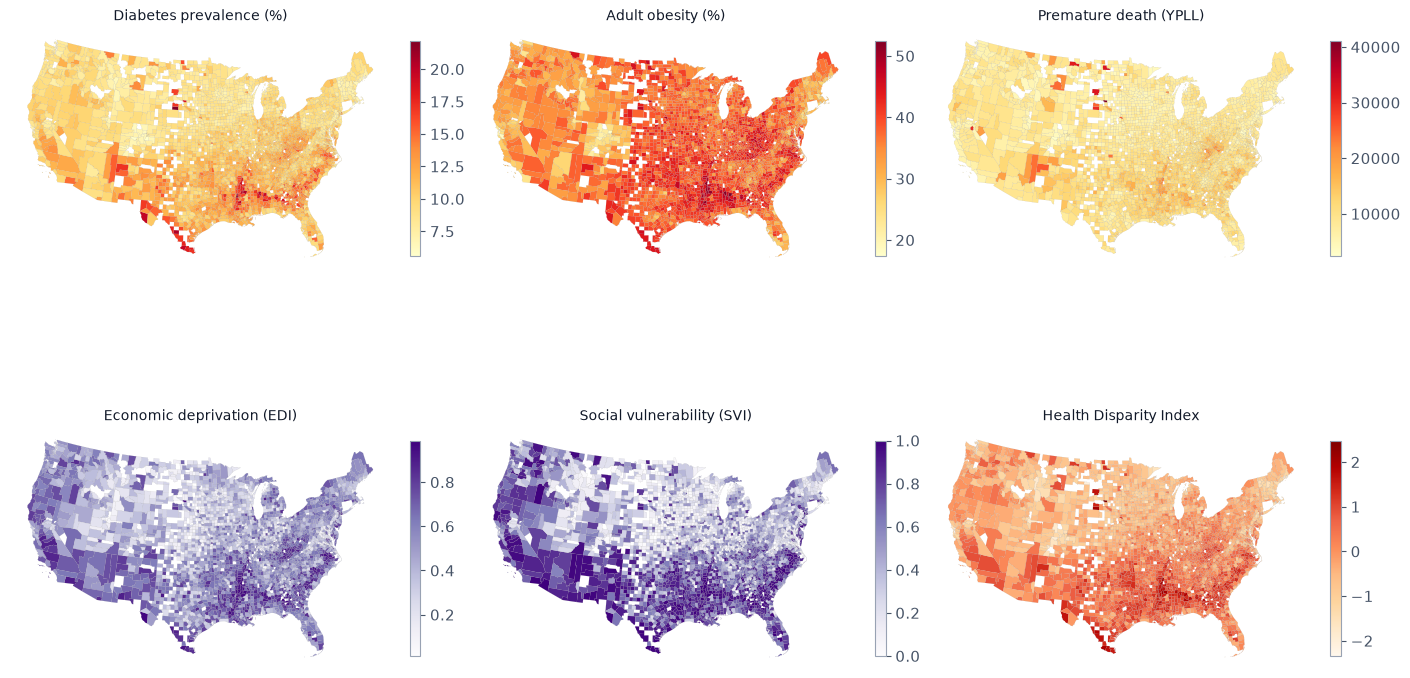

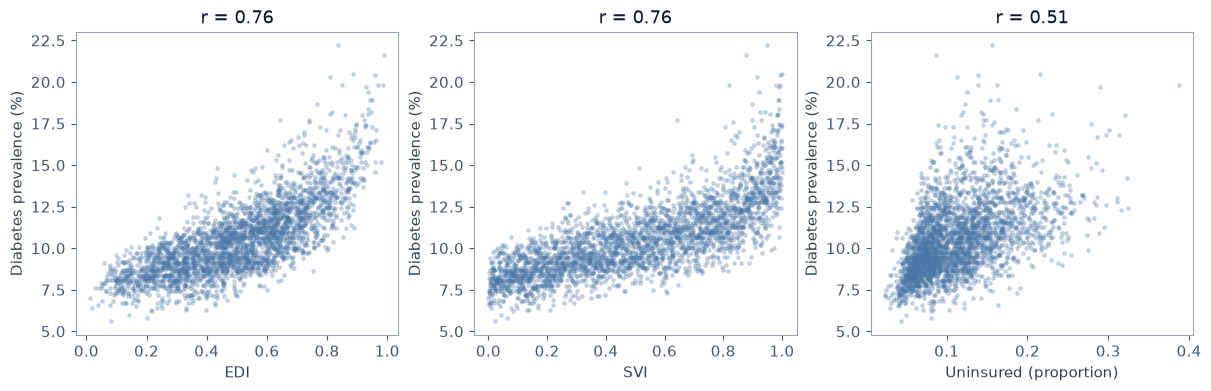

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
map_specs = [
    ("diabetes_pct", "YlOrRd", "Diabetes prevalence (%)"),
    ("obesity_pct", "YlOrRd", "Adult obesity (%)"),
    ("premature_death", "YlOrRd", "Premature death (YPLL)"),
    ("edi", "Purples", "Economic deprivation (EDI)"),
    ("svi", "Purples", "Social vulnerability (SVI)"),
    ("hdi", "OrRd", "Health Disparity Index"),
]
for ax, (col, cmap, title) in zip(axes.ravel(), map_specs):
    counties.plot(
        column=col, cmap=cmap, linewidth=0.05, edgecolor="0.5", ax=ax,
        legend=True, legend_kwds={"shrink": 0.55},
    )
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), constrained_layout=True)
for ax, xcol, xlabel in [
    (axes[0], "edi", "EDI"),
    (axes[1], "svi", "SVI"),
    (axes[2], "uninsured", "Uninsured (proportion)"),
]:
    ax.scatter(counties[xcol], counties["diabetes_pct"], s=6, alpha=0.25, color="#4C78A8")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Diabetes prevalence (%)")
    r = np.corrcoef(counties[xcol], counties["diabetes_pct"])[0, 1]
    ax.set_title(f"r = {r:.2f}")
plt.show()


### Bivariate choropleth: deprivation and diabetes

A 3 x 3 tercile map shows the joint distribution of EDI and diabetes prevalence. Dark counties are in the top tercile of both.

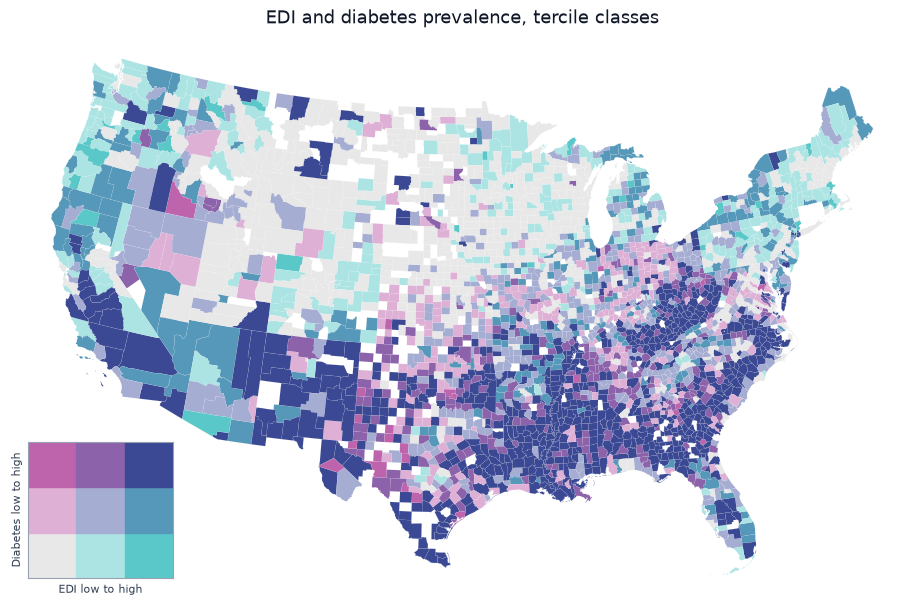

,EDI low,EDI mid,EDI high
Diabetes low,651,286,29
Diabetes mid,290,442,233
Diabetes high,25,237,704


**704** counties (**24%**) are in the top tercile of both EDI and diabetes; independence would put about **322** there.

In [7]:
BIV_COLORS = {  # (EDI tercile, diabetes tercile)
    (0, 0): "#e8e8e8", (1, 0): "#ace4e4", (2, 0): "#5ac8c8",
    (0, 1): "#dfb0d6", (1, 1): "#a5add3", (2, 1): "#5698b9",
    (0, 2): "#be64ac", (1, 2): "#8c62aa", (2, 2): "#3b4994",
}
counties["edi_t"] = pd.qcut(counties["edi"], 3, labels=False)
counties["diab_t"] = pd.qcut(counties["diabetes_pct"].rank(method="first"), 3, labels=False)
biv_color = [BIV_COLORS[(int(a), int(b))] for a, b in zip(counties["edi_t"], counties["diab_t"])]

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
counties.plot(color=biv_color, edgecolor="white", linewidth=0.05, ax=ax)
ax.set_title("EDI and diabetes prevalence, tercile classes")
ax.set_axis_off()
leg = ax.inset_axes([0.02, 0.04, 0.16, 0.24])
for (a, b), col in BIV_COLORS.items():
    leg.add_patch(plt.Rectangle((a, b), 1, 1, color=col))
leg.set_xlim(0, 3)
leg.set_ylim(0, 3)
leg.set_xticks([])
leg.set_yticks([])
leg.set_xlabel("EDI low to high", fontsize=8)
leg.set_ylabel("Diabetes low to high", fontsize=8)
plt.show()

joint = pd.crosstab(counties["diab_t"], counties["edi_t"])
joint.index = ["Diabetes low", "Diabetes mid", "Diabetes high"]
joint.columns = ["EDI low", "EDI mid", "EDI high"]
display(joint)
both_high = int(joint.loc["Diabetes high", "EDI high"])
display(Markdown(
    f"**{both_high:,}** counties (**{both_high / len(counties) * 100:.0f}%**) are in the top tercile of both EDI and diabetes; "
    f"independence would put about **{len(counties) / 9:.0f}** there."
))

## Spatial weights and global Moran's I

Queen contiguity with nearest-neighbor linking for any islands. Global Moran's I for each outcome and for EDI tests whether similar values cluster geographically.


Spatial Weights (W)
  Observations        2897
  Transform           row
  Min neighbors       1
  Mean neighbors      5.533
  Max neighbors       13
  Islands             0
  Components          1
  Nonzero weights     16030


Raw Queen had **2** island(s); after linking, **0** remain in **1** component(s).

,I,z,p_value
variable,,,
Diabetes %,0.670,58.13,0.0010
Obesity %,0.611,53.04,0.0010
Premature death,0.484,42.08,0.0010
EDI,0.471,40.88,0.0010
SVI,0.524,45.50,0.0010
HDI,0.657,57.01,0.0010


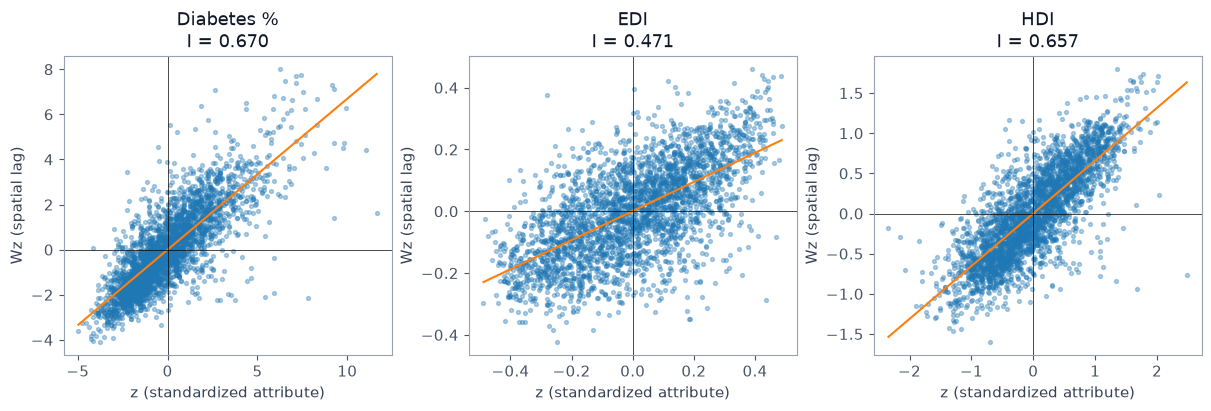

Diabetes Moran's I = **0.670** (p = **0.0010**), supporting spatial clustering of health burden.

In [8]:
def attach_islands(w, xy):
    """Link each island to its nearest non-island county, both ways, then row-standardise."""
    ids = list(w.id_order)
    pos = {i: k for k, i in enumerate(ids)}
    islands = set(w.islands())
    neighbors = {i: list(w.neighbors[i]) for i in ids}
    if not islands:
        return W(neighbors, ids=ids, transform="row")
    tree = cKDTree(xy)
    for isl in islands:
        _, idxs = tree.query(xy[pos[isl]], k=min(25, len(ids)))
        for j in np.atleast_1d(idxs):
            other = ids[int(j)]
            if other == isl or other in islands:
                continue
            if other not in neighbors[isl]:
                neighbors[isl].append(other)
            if isl not in neighbors[other]:
                neighbors[other].append(isl)
            break
    return W(neighbors, ids=ids, transform="row")


w_raw = Queen(counties, transform="row")
w = attach_islands(w_raw, coords)
print(w.summary())
display(Markdown(
    f"Raw Queen had **{len(w_raw.islands())}** island(s); after linking, "
    f"**{len(w.islands())}** remain in **{w.n_components()}** component(s)."
))

moran_targets = {
    "diabetes_pct": "Diabetes %",
    "obesity_pct": "Obesity %",
    "premature_death": "Premature death",
    "edi": "EDI",
    "svi": "SVI",
    "hdi": "HDI",
}
moran_rows = []
morans = {}
for col, label in moran_targets.items():
    mi = Moran(counties[col].to_numpy(float), w, permutations=PERM, seed=SEED)
    morans[col] = mi
    moran_rows.append({"variable": label, "I": mi.I, "z": mi.z_score, "p_value": mi.p_value})
moran_tbl = pd.DataFrame(moran_rows).set_index("variable")
display(moran_tbl.style.format({"I": "{:.3f}", "z": "{:.2f}", "p_value": "{:.4f}"}))

fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, col in zip(axes, ["diabetes_pct", "edi", "hdi"]):
    moran_scatter(morans[col], ax=ax, s=8, alpha=0.35)
    ax.set_title(f"{moran_targets[col]}\nI = {morans[col].I:.3f}")
plt.show()
display(Markdown(
    f"Diabetes Moran's I = **{morans['diabetes_pct'].I:.3f}** "
    f"(p = **{morans['diabetes_pct'].p_value:.4f}**), supporting spatial clustering of health burden."
))


### Sensitivity to the weights definition

The guideline lists Queen contiguity and k-nearest neighbors as the two common choices. Moran's I is recomputed with KNN (k = 6) on county centroids to confirm the clustering result does not depend on the contiguity definition.

In [9]:
w_knn = KNN(coords, k=6, transform="row")
sens_rows = []
for col, label in moran_targets.items():
    mk = Moran(counties[col].to_numpy(float), w_knn, permutations=PERM, seed=SEED)
    sens_rows.append({
        "variable": label, "I_queen": morans[col].I, "I_knn6": mk.I, "p_knn6": mk.p_value,
    })
sens_tbl = pd.DataFrame(sens_rows).set_index("variable")
display(sens_tbl.style.format({"I_queen": "{:.3f}", "I_knn6": "{:.3f}", "p_knn6": "{:.4f}"}))
max_gap = (sens_tbl["I_queen"] - sens_tbl["I_knn6"]).abs().max()
display(Markdown(
    f"The largest absolute difference between Queen and KNN-6 Moran's I is **{max_gap:.3f}**. "
    f"Queen contiguity (with islands linked) is used for the rest of the notebook."
))

,I_queen,I_knn6,p_knn6
variable,,,
Diabetes %,0.670,0.666,0.0010
Obesity %,0.611,0.612,0.0010
Premature death,0.484,0.479,0.0010
EDI,0.471,0.464,0.0010
SVI,0.524,0.512,0.0010
HDI,0.657,0.655,0.0010


The largest absolute difference between Queen and KNN-6 Moran's I is **0.012**. Queen contiguity (with islands linked) is used for the rest of the notebook.

## Local clusters: LISA and Gi* for diabetes

Local Moran's I labels HH / LL / HL / LH clusters. Gi* highlights hot and cold spots. The first map uses uncorrected permutation p-values at alpha = 0.05 alongside analytic Gi*; the next cell applies the false discovery rate correction the guideline recommends for reporting.

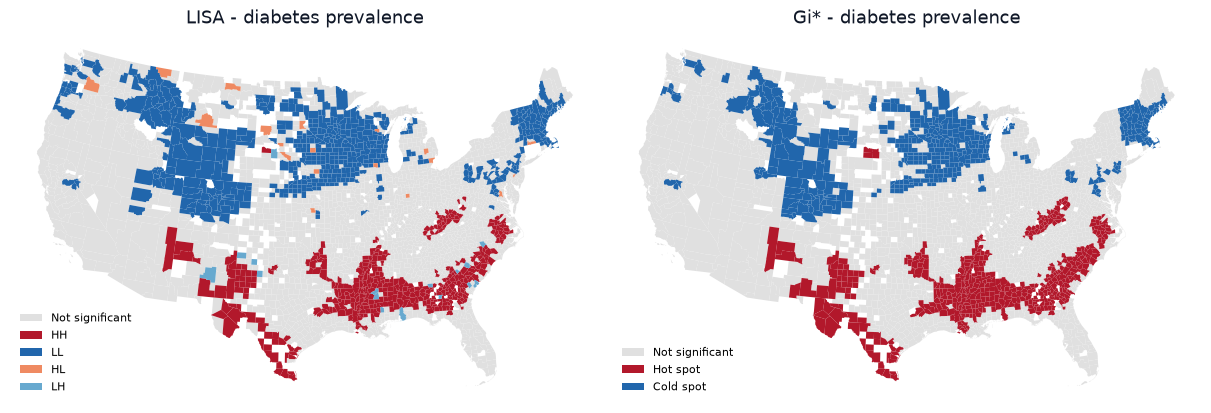

**LISA (uncorrected)**

,label,n
0,Not significant,1956
1,LL,519
2,HH,387
3,HL,19
4,LH,16


**Gi* (grouped)**

,label,n
0,Not significant,2035
1,Hot spot,450
2,Cold spot,412


In [10]:
y_diab = counties["diabetes_pct"].to_numpy(float)
lisa = local_moran_clusters(
    y_diab, w, permutations=PERM, correction="none", alpha=ALPHA, seed=SEED
)
gi = getis_ord_gi(y_diab, w, star=True, inference="analytic", alpha=ALPHA, seed=SEED)

def gi_group(label: str) -> str:
    lab = str(label)
    if lab.startswith("Hot"):
        return "Hot spot"
    if lab.startswith("Cold"):
        return "Cold spot"
    return "Not significant"

counties["lisa_diabetes"] = list(lisa.labels)
counties["gi_diabetes"] = [gi_group(x) for x in gi.labels]

LISA_COLORS = {
    "Not significant": "#e0e0e0",
    "HH": "#b2182b",
    "LL": "#2166ac",
    "HL": "#ef8a62",
    "LH": "#67a9cf",
}
GI_COLORS = {
    "Not significant": "#e0e0e0",
    "Hot spot": "#b2182b",
    "Cold spot": "#2166ac",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), constrained_layout=True)
for ax, col, palette, title in [
    (axes[0], "lisa_diabetes", LISA_COLORS, "LISA - diabetes prevalence"),
    (axes[1], "gi_diabetes", GI_COLORS, "Gi* - diabetes prevalence"),
]:
    for label, color in palette.items():
        part = counties[counties[col] == label]
        if len(part):
            part.plot(ax=ax, color=color, edgecolor="none", linewidth=0, label=label)
    ax.set_title(title)
    ax.set_axis_off()
    ax.legend(loc="lower left", fontsize=8, frameon=False)
plt.show()

display(Markdown("**LISA (uncorrected)**"))
display(counties["lisa_diabetes"].value_counts().rename_axis("label").reset_index(name="n"))
display(Markdown("**Gi* (grouped)**"))
display(counties["gi_diabetes"].value_counts().rename_axis("label").reset_index(name="n"))


### LISA with false discovery rate control

Each county is a separate test, so the uncorrected map above overstates the number of clusters. The guideline recommends the Benjamini-Hochberg procedure. With FDR the smallest attainable permutation p-value matters, so the local statistic is rerun with more permutations (`PERM_LOCAL`).

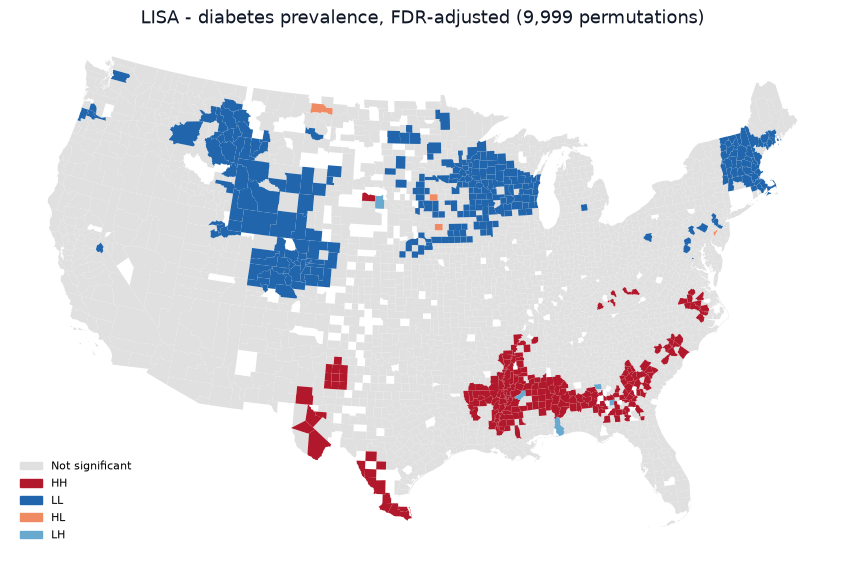

FDR,HH,LL,HL,LH,Not significant
uncorrected,,,,,
HH,208,0,0,0,179
LL,0,288,0,0,231
HL,0,0,4,0,15
LH,0,0,0,5,11
Not significant,0,0,0,0,1956


FDR keeps **505** of **941** uncorrected significant counties (**54%**). High-High counties fall from **387** to **208**. The FDR map is the one to report; the uncorrected map is kept for comparison.

In [11]:
def lisa_fdr_clusters(values):
    # FDR-adjusted LISA. The resolution warning is silenced: it flags that few counties may
    # survive FDR at this permutation count, and the counts reported below show that many do.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        return local_moran_clusters(
            values, w, permutations=PERM_LOCAL, correction="fdr", alpha=ALPHA, seed=SEED
        )


lisa_fdr = lisa_fdr_clusters(y_diab)
counties["lisa_diabetes_fdr"] = list(lisa_fdr.labels)

fig, ax = plt.subplots(figsize=(8.5, 5.5), constrained_layout=True)
for label, color in LISA_COLORS.items():
    part = counties[counties["lisa_diabetes_fdr"] == label]
    if len(part):
        part.plot(ax=ax, color=color, edgecolor="none", linewidth=0, label=label)
ax.legend(
    handles=[Patch(color=c, label=l) for l, c in LISA_COLORS.items()],
    loc="lower left", fontsize=8, frameon=False,
)
ax.set_title(f"LISA - diabetes prevalence, FDR-adjusted ({PERM_LOCAL:,} permutations)")
ax.set_axis_off()
plt.show()

order = ["HH", "LL", "HL", "LH", "Not significant"]
lisa_cmp = pd.crosstab(
    counties["lisa_diabetes"], counties["lisa_diabetes_fdr"],
    rownames=["uncorrected"], colnames=["FDR"],
).reindex(index=order, columns=order, fill_value=0)
display(lisa_cmp)

n_unc = int((counties["lisa_diabetes"] != "Not significant").sum())
n_fdr = int((counties["lisa_diabetes_fdr"] != "Not significant").sum())
hh_unc = int((counties["lisa_diabetes"] == "HH").sum())
hh_fdr = int((counties["lisa_diabetes_fdr"] == "HH").sum())
display(Markdown(
    f"FDR keeps **{n_fdr:,}** of **{n_unc:,}** uncorrected significant counties "
    f"(**{n_fdr / n_unc * 100:.0f}%**). High-High counties fall from **{hh_unc}** to **{hh_fdr}**. "
    f"The FDR map is the one to report; the uncorrected map is kept for comparison."
))

## Bivariate spatial association: EDI and diabetes

Bivariate Moran's I correlates local EDI with the spatial lag of diabetes (and the reverse), after z-scoring both variables so the statistic is on a correlation-like scale. This asks whether deprived counties sit near high-diabetes neighbors. Bivariate LISA then shows where.

,pair,I,p_value
0,EDI vs lag(diabetes),0.453,0.0010
1,Diabetes vs lag(EDI),0.453,0.0010


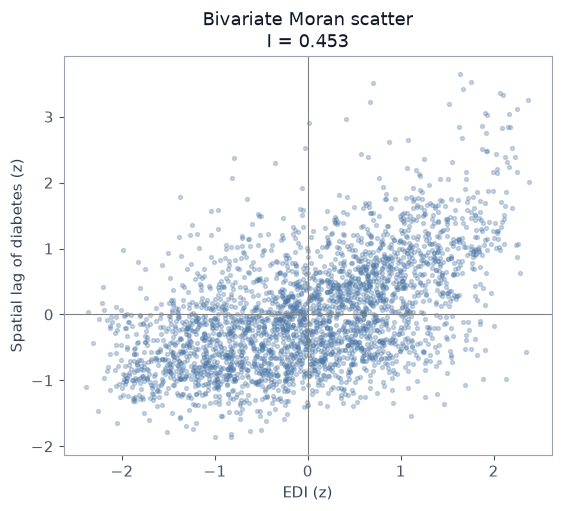

Bivariate Moran's I (EDI vs lag of diabetes) = **0.453** (p = **0.0010**).

In [12]:
x_edi = counties["edi"].to_numpy(float)
y_diab = counties["diabetes_pct"].to_numpy(float)
# Z-score both sides so bivariate I is on a correlation-like scale
# (raw EDI vs diabetes % mixes 0-1 ranks with percentage points).
x_z = (x_edi - x_edi.mean()) / x_edi.std(ddof=0)
y_z = (y_diab - y_diab.mean()) / y_diab.std(ddof=0)
bv_edi_diab = MoranBV(x_z, y_z, w, permutations=PERM, seed=SEED)
bv_diab_edi = MoranBV(y_z, x_z, w, permutations=PERM, seed=SEED)

bv_tbl = pd.DataFrame(
    [
        {"pair": "EDI vs lag(diabetes)", "I": bv_edi_diab.I, "p_value": bv_edi_diab.p_value},
        {"pair": "Diabetes vs lag(EDI)", "I": bv_diab_edi.I, "p_value": bv_diab_edi.p_value},
    ]
)
display(bv_tbl.style.format({"I": "{:.3f}", "p_value": "{:.4f}"}))

# Quadrant view: EDI (x) vs spatial lag of diabetes
w_diab = w.sparse @ y_z
fig, ax = plt.subplots(figsize=(5.5, 5), constrained_layout=True)
ax.axhline(0, color="0.5", lw=0.8)
ax.axvline(0, color="0.5", lw=0.8)
ax.scatter(x_z, w_diab, s=8, alpha=0.3, color="#4C78A8")
ax.set_xlabel("EDI (z)")
ax.set_ylabel("Spatial lag of diabetes (z)")
ax.set_title(f"Bivariate Moran scatter\nI = {bv_edi_diab.I:.3f}")
plt.show()
display(Markdown(
    f"Bivariate Moran's I (EDI vs lag of diabetes) = **{bv_edi_diab.I:.3f}** "
    f"(p = **{bv_edi_diab.p_value:.4f}**)."
))


### Bivariate LISA: where deprivation meets high-diabetes neighborhoods

Bivariate local Moran's I locates the association measured above. A High-High county has high EDI and is surrounded by counties with high diabetes prevalence. P-values are FDR-adjusted.

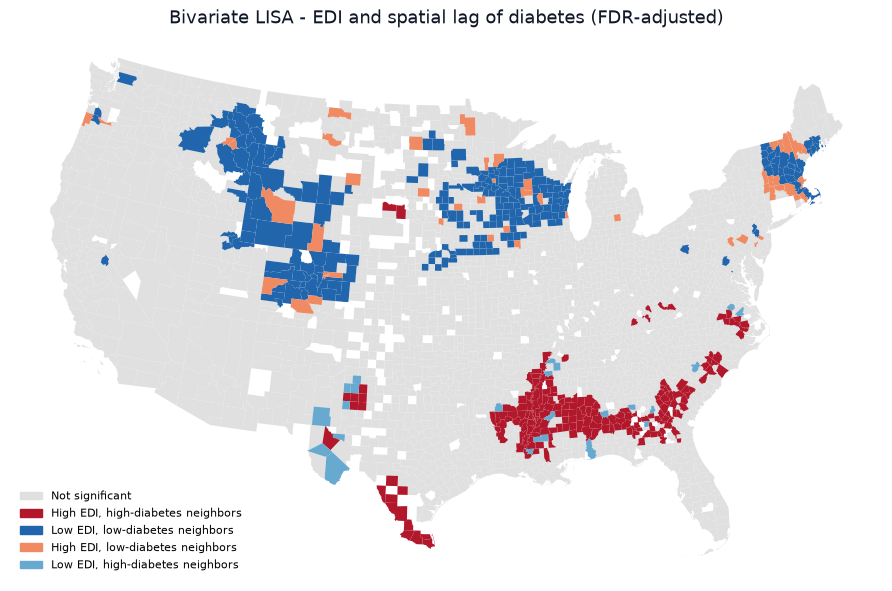

,class,n
0,"High EDI, high-diabetes neighbors",187
1,"Low EDI, low-diabetes neighbors",239
2,"High EDI, low-diabetes neighbors",51
3,"Low EDI, high-diabetes neighbors",24
4,Not significant,2396


**187** counties combine high deprivation with high-diabetes neighbors and **239** combine low deprivation with low-diabetes neighbors. The High-High class is concentrated in **Mississippi** (44), **Georgia** (41), **Alabama** (24), **Louisiana** (22), **Texas** (17).

In [13]:
bv_local = Moran_Local_BV(
    x_edi, y_diab, w, permutations=PERM_LOCAL, seed=SEED, alpha=ALPHA, fdr=True
)
counties["bv_lisa"] = ["Not significant" if lab == "NS" else lab for lab in bv_local.labels]

BV_NAMES = {
    "HH": "High EDI, high-diabetes neighbors",
    "LL": "Low EDI, low-diabetes neighbors",
    "HL": "High EDI, low-diabetes neighbors",
    "LH": "Low EDI, high-diabetes neighbors",
    "Not significant": "Not significant",
}
fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)
for label, color in LISA_COLORS.items():
    part = counties[counties["bv_lisa"] == label]
    if len(part):
        part.plot(ax=ax, color=color, edgecolor="none", linewidth=0)
ax.legend(
    handles=[Patch(color=c, label=BV_NAMES[l]) for l, c in LISA_COLORS.items()],
    loc="lower left", fontsize=8, frameon=False,
)
ax.set_title("Bivariate LISA - EDI and spatial lag of diabetes (FDR-adjusted)")
ax.set_axis_off()
plt.show()

bv_counts = counties["bv_lisa"].value_counts().reindex(list(BV_NAMES), fill_value=0)
display(bv_counts.rename(index=BV_NAMES).rename_axis("class").reset_index(name="n"))
bv_hh_states = counties.loc[counties["bv_lisa"] == "HH", "STATE"].value_counts().head(5)
display(Markdown(
    f"**{int(bv_counts['HH'])}** counties combine high deprivation with high-diabetes neighbors and "
    f"**{int(bv_counts['LL'])}** combine low deprivation with low-diabetes neighbors. "
    f"The High-High class is concentrated in "
    + ", ".join(f"**{s}** ({n})" for s, n in bv_hh_states.items())
    + "."
))

## Regression models of diabetes disparities

OLS baseline, then spatial lag (SAR), spatial error (SEM), and spatial Durbin (SDM), which adds the neighbors' predictors (`W_x`) to the lag model. Predictors: EDI, SVI, uninsured, PCP, PM2.5, and percent rural. Check VIF before fitting.

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_raw = counties[PREDICTORS].to_numpy(dtype=float)
X_std = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0, ddof=0)
y = counties["diabetes_pct"].to_numpy(dtype=float)

vif_tbl = pd.DataFrame({
    "predictor": [PRED_LABELS[c] for c in PREDICTORS],
    "VIF": [variance_inflation_factor(np.column_stack([np.ones(len(X_std)), X_std]), i + 1)
            for i in range(X_std.shape[1])],
}).set_index("predictor")
display(vif_tbl.style.format("{:.2f}"))

ols = OLS(y, X_std, w=w, names=PREDICTORS, y_name="diabetes_pct")
sar = SpatialLag(y, X_std, w, names=PREDICTORS, y_name="diabetes_pct")
sem = SpatialError(y, X_std, w, names=PREDICTORS, y_name="diabetes_pct")
sdm = SpatialDurbin(y, X_std, w, names=PREDICTORS, y_name="diabetes_pct")

comp = compare_models({"OLS": ols, "Spatial lag": sar, "Spatial error": sem, "Spatial Durbin": sdm})
display(Markdown("### Model comparison"))
display(comp)

display(Markdown("### OLS coefficients (standardized predictors)"))
display(pd.DataFrame(
    {"beta": np.asarray(ols.beta).reshape(-1), "pval": np.asarray(ols.pvals).reshape(-1)},
    index=["intercept", *PREDICTORS],
).style.format({"beta": "{:.3f}", "pval": "{:.4f}"}))

mi_ols = ols.residual_moran()
mi_sar = sar.residual_moran()
mi_sem = sem.residual_moran()
mi_sdm = sdm.residual_moran()
resid_tbl = pd.DataFrame(
    [
        {"model": "OLS", "resid_I": mi_ols["I"], "p": mi_ols["p_value"]},
        {"model": "Spatial lag", "resid_I": mi_sar["I"], "p": mi_sar["p_value"]},
        {"model": "Spatial error", "resid_I": mi_sem["I"], "p": mi_sem["p_value"]},
        {"model": "Spatial Durbin", "resid_I": mi_sdm["I"], "p": mi_sdm["p_value"]},
    ]
)
display(Markdown("### Residual Moran's I"))
display(resid_tbl.style.format({"resid_I": "{:.3f}", "p": "{:.4f}"}))
display(Markdown(
    f"OLS residual Moran I = **{mi_ols['I']:.3f}**. "
    f"Spatial lag / error / Durbin models absorb most of the neighboring structure "
    f"(residual I = **{mi_sar['I']:.3f}** / **{mi_sem['I']:.3f}** / **{mi_sdm['I']:.3f}**)."
))


,VIF
predictor,
Economic deprivation (EDI),5.75
SVI overall,7.62
% uninsured,1.89
Primary care physicians,1.26
PM2.5,1.14
% rural,1.39


### Model comparison

,n_params,loglik,aic,bic,pseudo_r2,rho,lambda,resid_moran_I,resid_moran_p
model,,,,,,,,,
OLS,7,-4581.799548,9177.599096,9219.399113,0.711703,NaN,NaN,0.491078,0.000000e+00
Spatial lag,8,-4026.838665,8069.677330,8117.448778,0.813202,0.481498,NaN,0.131112,0.000000e+00
Spatial error,8,-3873.927823,7763.855646,7811.627094,0.705898,NaN,0.740339,-0.069809,1.619672e-09
Spatial Durbin,14,-3831.682542,7691.365084,7774.965118,0.848294,0.697073,NaN,-0.059738,2.499809e-07


### OLS coefficients (standardized predictors)

,beta,pval
intercept,10.561,0.0000
edi,1.136,0.0000
svi,0.318,0.0000
uninsured,0.512,0.0000
pcp,-0.219,0.0000
pm25,0.338,0.0000
pct_rural,0.235,0.0000


### Residual Moran's I

,model,resid_I,p
0,OLS,0.491,0.0000
1,Spatial lag,0.131,0.0000
2,Spatial error,-0.070,0.0000
3,Spatial Durbin,-0.060,0.0000


OLS residual Moran I = **0.491**. Spatial lag / error / Durbin models absorb most of the neighboring structure (residual I = **0.131** / **-0.070** / **-0.060**).

### OLS diagnostics, model choice, and spillovers

The guideline asks for heteroskedasticity and residual diagnostics, and for a decision between the lag, error, and Durbin specifications. Lagrange Multiplier tests on the OLS residuals point to the form of spatial dependence, likelihood-ratio tests check whether the Durbin terms (`W_x`) can be dropped, and the Durbin impacts split each association into a direct (own-county) and an indirect (neighboring-county) part.

,statistic,p_value
diagnostic,,
Breusch-Pagan (heteroskedasticity),190.40,2.092e-38
Jarque-Bera (normality),2291.38,0
Condition number,5.61,


### Lagrange Multiplier tests on OLS residuals

,statistic,df,p_value
test,,,
LM-Lag,1230.3,1,1.58e-269
Robust LM-Lag,124.5,1,6.48e-29
LM-Error,1810.4,1,0
Robust LM-Error,704.6,1,2.97e-155
LM-SARMA,1934.9,2,0


LM recommendation: Spatial error model (both robust tests significant; larger statistic chosen — consider SARMA/Durbin)


### Likelihood-ratio tests against the spatial Durbin model

,restricted,full,statistic,df,p_value
0,Spatial lag,Spatial Durbin,390.3,6,3.38e-81
1,Spatial error,Spatial Durbin,84.5,6,4.21e-16


### Spatial Durbin impacts (pp diabetes per SD of each predictor, 95% simulation intervals)

,direct,direct_lo,direct_hi,indirect,indirect_lo,indirect_hi,total,total_lo,total_hi
Economic deprivation (EDI),0.958,0.864,1.051,0.524,0.167,0.847,1.481,1.096,1.845
SVI overall,0.334,0.235,0.434,-0.188,-0.551,0.235,0.146,-0.273,0.590
% uninsured,0.370,0.285,0.448,0.155,-0.040,0.346,0.525,0.330,0.714
Primary care physicians,-0.185,-0.229,-0.144,-0.364,-0.605,-0.141,-0.549,-0.811,-0.307
PM2.5,0.090,0.023,0.162,0.184,0.054,0.321,0.274,0.150,0.413
% rural,0.148,0.101,0.193,0.088,-0.081,0.272,0.236,0.049,0.429


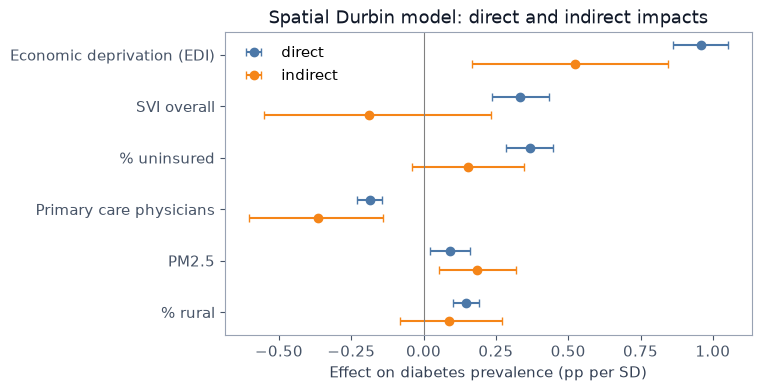

Breusch-Pagan p = **2.09e-38**, so OLS standard errors are not reliable as they stand. Both LR tests reject the restricted models (p = **3.4e-81** and **4.2e-16**), and **Spatial Durbin** has the lowest AIC. In the Durbin model one SD of EDI is associated with **0.96** pp higher diabetes in the same county and **0.52** pp (95% interval 0.17 to 0.85) through neighboring counties. These are associations under the model, not causal spillovers.

In [15]:
bp = ols.breusch_pagan()
jb = ols.jarque_bera()
diag_tbl = pd.DataFrame(
    [
        {"diagnostic": "Breusch-Pagan (heteroskedasticity)", "statistic": bp["statistic"], "p_value": bp["p_value"]},
        {"diagnostic": "Jarque-Bera (normality)", "statistic": jb["statistic"], "p_value": jb["p_value"]},
        {"diagnostic": "Condition number", "statistic": ols.condition_number, "p_value": np.nan},
    ]
).set_index("diagnostic")
display(diag_tbl.style.format({"statistic": "{:.2f}", "p_value": "{:.4g}"}, na_rep=""))

lm = ols.lm_tests()
display(Markdown("### Lagrange Multiplier tests on OLS residuals"))
display(lm.to_frame().set_index("test").style.format({"statistic": "{:.1f}", "p_value": "{:.3g}"}))
print("LM recommendation:", lm.recommendation())

lr_sar = lr_test(sar, sdm)
lr_sem = lr_test(sem, sdm)
lr_tbl = pd.DataFrame(
    [
        {"restricted": "Spatial lag", "full": "Spatial Durbin", **lr_sar},
        {"restricted": "Spatial error", "full": "Spatial Durbin", **lr_sem},
    ]
)
display(Markdown("### Likelihood-ratio tests against the spatial Durbin model"))
display(lr_tbl.style.format({"statistic": "{:.1f}", "p_value": "{:.3g}"}))

impacts = sdm.impacts(nsim=1000, seed=SEED).set_index("variable")
impacts.index = [PRED_LABELS[c] for c in impacts.index]
display(Markdown("### Spatial Durbin impacts (pp diabetes per SD of each predictor, 95% simulation intervals)"))
display(impacts.style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(7.5, 3.8), constrained_layout=True)
pos = np.arange(len(impacts))
for off, kind, color in [(-0.18, "direct", "#4C78A8"), (0.18, "indirect", "#F58518")]:
    est = impacts[kind].to_numpy()
    err = np.vstack([est - impacts[f"{kind}_lo"].to_numpy(), impacts[f"{kind}_hi"].to_numpy() - est])
    ax.errorbar(est, pos + off, xerr=err, fmt="o", color=color, capsize=3, label=kind)
ax.axvline(0, color="0.5", lw=0.8)
ax.set_yticks(pos)
ax.set_yticklabels(impacts.index)
ax.invert_yaxis()
ax.set_xlabel("Effect on diabetes prevalence (pp per SD)")
ax.set_title("Spatial Durbin model: direct and indirect impacts")
ax.legend(frameon=False)
plt.show()

edi_lab = PRED_LABELS["edi"]
best_aic = comp["aic"].idxmin()
display(Markdown(
    f"Breusch-Pagan p = **{bp['p_value']:.3g}**, so OLS standard errors are not reliable as they stand. "
    f"Both LR tests reject the restricted models (p = **{lr_sar['p_value']:.2g}** and **{lr_sem['p_value']:.2g}**), "
    f"and **{best_aic}** has the lowest AIC. "
    f"In the Durbin model one SD of EDI is associated with **{impacts.loc[edi_lab, 'direct']:.2f}** pp higher diabetes "
    f"in the same county and **{impacts.loc[edi_lab, 'indirect']:.2f}** pp "
    f"(95% interval {impacts.loc[edi_lab, 'indirect_lo']:.2f} to {impacts.loc[edi_lab, 'indirect_hi']:.2f}) through neighboring counties. "
    f"These are associations under the model, not causal spillovers."
))

## Geographically weighted regression

GWR lets the EDI-diabetes slope vary across counties. A coarse adaptive-bandwidth grid picks the AICc-minimizing neighbor count. MGWR then relaxes the single-bandwidth assumption for one region.

,k,aicc,rmse
0,100,1453.35,0.70
1,200,1822.72,0.79
2,400,2235.25,0.87


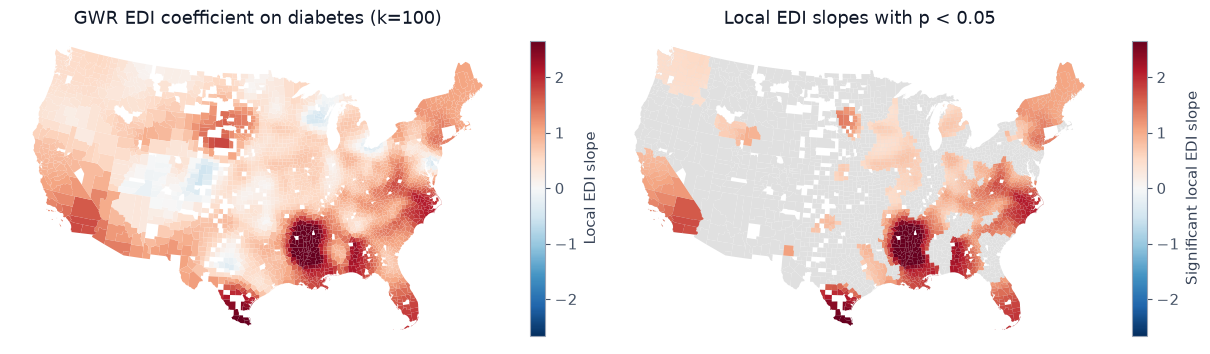

Best adaptive bandwidth **k = 100** (AICc 1453.4). Local EDI slopes range from **-0.56** to **4.09** pp diabetes per SD EDI; **50%** of counties have uncorrected local p < 0.05.

In [16]:
gwr_rows, gwr_fits = [], {}
for k in (100, 200, 400):
    fit = GWR(
        bandwidth=k, fixed=False, kernel="bisquare",
        criterion="AICc", hat_matrix=True, n_jobs=-1,
    )
    fit.fit(X_std, y, coords)
    gwr_fits[k] = fit
    gwr_rows.append({
        "k": k,
        "aicc": fit.aicc_,
        "rmse": float(np.sqrt(np.mean(fit.residuals_ ** 2))),
    })
gwr_grid = pd.DataFrame(gwr_rows).sort_values("aicc").reset_index(drop=True)
display(gwr_grid.round(2))
best_k = int(gwr_grid.loc[0, "k"])
gwr = gwr_fits[best_k]

# coef_ column 0 = intercept; predictors follow PREDICTORS order
edi_idx = 1 + PREDICTORS.index("edi")
counties["gwr_edi"] = gwr.coef_[:, edi_idx]
local_p = gwr.p_values_[:, edi_idx]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
lim = float(np.nanpercentile(np.abs(counties["gwr_edi"]), 98))
counties.plot(
    column="gwr_edi", cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim),
    legend=True, ax=axes[0], edgecolor="none",
    legend_kwds={"shrink": 0.6, "label": "Local EDI slope"},
)
axes[0].set_title(f"GWR EDI coefficient on diabetes (k={best_k})")
axes[0].set_axis_off()

sig = counties.copy()
sig["edi_sig"] = np.where(local_p < ALPHA, counties["gwr_edi"], np.nan)
sig.plot(color="#e0e0e0", ax=axes[1], edgecolor="none")
sig.dropna(subset=["edi_sig"]).plot(
    column="edi_sig", cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim),
    legend=True, ax=axes[1], edgecolor="none",
    legend_kwds={"shrink": 0.6, "label": "Significant local EDI slope"},
)
axes[1].set_title(f"Local EDI slopes with p < {ALPHA}")
axes[1].set_axis_off()
plt.show()

display(Markdown(
    f"Best adaptive bandwidth **k = {best_k}** (AICc {gwr.aicc_:.1f}). "
    f"Local EDI slopes range from **{counties['gwr_edi'].min():.2f}** to "
    f"**{counties['gwr_edi'].max():.2f}** pp diabetes per SD EDI; "
    f"**{(local_p < ALPHA).mean() * 100:.0f}%** of counties have uncorrected local p < {ALPHA}."
))


### MGWR: covariate-specific scales in the Deep South

GWR forces one bandwidth on every coefficient. MGWR estimates a separate bandwidth for each predictor, so a process that is nearly regional can be told apart from one that changes over short distances. This cell uses the PySAL `mgwr` package, the Python MGWR library named in the guideline, because its back-fitting bandwidth search and local standard errors are well tested. The search is slow for about 2,900 counties, so the model is fitted to the five Deep South states that hold most High-High diabetes counties (`MGWR_STATES`). Predictors are re-standardized within the region, which makes the bandwidths comparable across terms. The cell is skipped if `mgwr` is not installed.

In [17]:
try:
    from mgwr.gwr import GWR as PysalGWR, MGWR as PysalMGWR
    from mgwr.sel_bw import Sel_BW
    HAVE_MGWR = True
except ImportError:
    HAVE_MGWR = False
    print("mgwr is not installed (pip install mgwr); the MGWR section is skipped.")

if HAVE_MGWR:
    in_region = counties["STATE"].isin(MGWR_STATES).to_numpy()
    region = counties.loc[in_region].copy()
    Xr = X_raw[in_region]
    Xr = (Xr - Xr.mean(axis=0)) / Xr.std(axis=0, ddof=0)
    yr = y[in_region].reshape(-1, 1)
    cr = coords[in_region]

    bw_gwr_r = Sel_BW(cr, yr, Xr).search()
    gwr_r = PysalGWR(cr, yr, Xr, bw_gwr_r).fit()
    mgwr_sel = Sel_BW(cr, yr, Xr, multi=True)
    mgwr_bws = mgwr_sel.search()
    mgwr_fit = PysalMGWR(cr, yr, Xr, mgwr_sel).fit()

    terms = ["Intercept", *[PRED_LABELS[c] for c in PREDICTORS]]
    t_filtered = mgwr_fit.filter_tvals()  # zero where not significant after the multiple-testing correction
    bw_tbl = pd.DataFrame(
        {
            "bandwidth (neighbors)": np.asarray(mgwr_bws, dtype=int),
            "share of region": np.asarray(mgwr_bws, dtype=float) / len(region),
            "effective params": mgwr_fit.ENP_j,
            "coef min": mgwr_fit.params.min(axis=0),
            "coef median": np.median(mgwr_fit.params, axis=0),
            "coef max": mgwr_fit.params.max(axis=0),
            "% counties significant": 100 * (t_filtered != 0).mean(axis=0),
        },
        index=terms,
    )
    display(bw_tbl.style.format({
        "share of region": "{:.0%}", "effective params": "{:.1f}", "coef min": "{:.2f}",
        "coef median": "{:.2f}", "coef max": "{:.2f}", "% counties significant": "{:.0f}",
    }))
    fit_tbl = pd.DataFrame(
        {"AICc": [gwr_r.aicc, mgwr_fit.aicc], "R2": [gwr_r.R2, mgwr_fit.R2],
         "effective params": [gwr_r.ENP, mgwr_fit.ENP]},
        index=[f"GWR (k={int(bw_gwr_r)})", "MGWR"],
    )
    display(fit_tbl.style.format({"AICc": "{:.1f}", "R2": "{:.3f}", "effective params": "{:.1f}"}))

    region["gwr_edi_r"] = gwr_r.params[:, edi_idx]
    region["mgwr_edi"] = mgwr_fit.params[:, edi_idx]
    lim = float(np.nanpercentile(np.abs(region[["gwr_edi_r", "mgwr_edi"]].to_numpy()), 98))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
    for ax, col, title in [
        (axes[0], "gwr_edi_r", f"GWR EDI slope (one bandwidth, k={int(bw_gwr_r)})"),
        (axes[1], "mgwr_edi", f"MGWR EDI slope (k={int(mgwr_bws[edi_idx])})"),
    ]:
        region.plot(
            column=col, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim),
            legend=True, ax=ax, edgecolor="white", linewidth=0.1,
            legend_kwds={"shrink": 0.6, "label": "pp diabetes per SD EDI"},
        )
        ax.set_title(title)
        ax.set_axis_off()
    plt.show()

    local_terms = bw_tbl.index[bw_tbl["share of region"] < 0.25].tolist()
    broad_terms = bw_tbl.index[bw_tbl["share of region"] > 0.75].tolist()
    display(Markdown(
        f"Region: **{len(region)}** counties in {', '.join(MGWR_STATES)}. "
        f"The single GWR bandwidth is **{int(bw_gwr_r)}** neighbors; MGWR bandwidths range from "
        f"**{int(min(mgwr_bws))}** to **{int(max(mgwr_bws))}**. "
        f"Short-range terms (under 25% of the region): **{', '.join(local_terms) or 'none'}**. "
        f"Near-regional terms (over 75%): **{', '.join(broad_terms) or 'none'}**. "
        f"AICc is **{mgwr_fit.aicc:.1f}** for MGWR and **{gwr_r.aicc:.1f}** for GWR. "
        f"The EDI slope is significant in **{bw_tbl.loc[PRED_LABELS['edi'], '% counties significant']:.0f}%** "
        f"of the region's counties after the MGWR multiple-testing correction."
    ))

mgwr is not installed (pip install mgwr); the MGWR section is skipped.


## Explainable machine learning (XGBoost + TreeSHAP)

State-grouped cross-validation avoids leaking neighboring counties across folds. TreeSHAP contributions (`pred_contribs`) summarize nonlinear feature importance for diabetes prevalence.


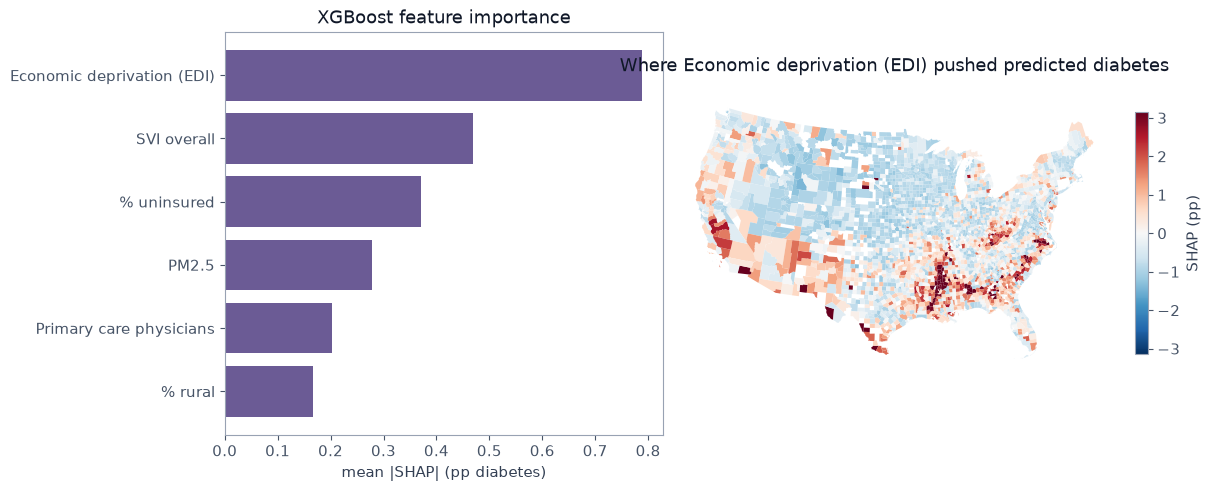

State-held-out R$^2$: XGBoost **0.73** vs standardized OLS **0.70**. Residual Moran I of out-of-fold errors = **0.429** (p = **0.0010**). Top TreeSHAP features: **Economic deprivation (EDI)**, **SVI overall**, **% uninsured**.

In [18]:
params = dict(
    n_estimators=400, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1,
)
groups = counties["STATE"].to_numpy()
oof = np.full(len(y), np.nan)
for train, test in GroupKFold(n_splits=8).split(X_raw, y, groups):
    model = xgb.XGBRegressor(**params).fit(X_raw[train], y[train])
    oof[test] = model.predict(X_raw[test])

ss_res = np.sum((y - oof) ** 2)
r2_cv = 1 - ss_res / np.sum((y - y.mean()) ** 2)

oof_ols = np.full(len(y), np.nan)
for train, test in GroupKFold(n_splits=8).split(X_std, y, groups):
    A = np.column_stack([np.ones(len(train)), X_std[train]])
    beta, *_ = np.linalg.lstsq(A, y[train], rcond=None)
    oof_ols[test] = np.column_stack([np.ones(len(test)), X_std[test]]) @ beta
r2_cv_ols = 1 - np.sum((y - oof_ols) ** 2) / np.sum((y - y.mean()) ** 2)

xgb_model = xgb.XGBRegressor(**params).fit(X_raw, y)
shap_vals = xgb_model.get_booster().predict(
    xgb.DMatrix(X_raw), pred_contribs=True
)[:, :-1]
shap_imp = pd.Series(
    np.abs(shap_vals).mean(axis=0),
    index=[PRED_LABELS[c] for c in PREDICTORS],
).sort_values()

resid_ml = y - oof
moran_ml = Moran(resid_ml, w, permutations=PERM, seed=SEED)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
axes[0].barh(shap_imp.index, shap_imp.values, color="#6B5B95")
axes[0].set_xlabel("mean |SHAP| (pp diabetes)")
axes[0].set_title("XGBoost feature importance")
top_feat = PREDICTORS[int(np.argmax(np.abs(shap_vals).mean(axis=0)))]
counties[f"shap_{top_feat}"] = shap_vals[:, PREDICTORS.index(top_feat)]
lim = float(np.nanpercentile(np.abs(counties[f"shap_{top_feat}"]), 98))
counties.plot(
    column=f"shap_{top_feat}", cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim),
    legend=True, ax=axes[1], edgecolor="none",
    legend_kwds={"shrink": 0.6, "label": "SHAP (pp)"},
)
axes[1].set_axis_off()
axes[1].set_title(f"Where {PRED_LABELS[top_feat]} pushed predicted diabetes")
plt.show()

display(Markdown(
    f"State-held-out R$^2$: XGBoost **{r2_cv:.2f}** vs standardized OLS **{r2_cv_ols:.2f}**. "
    f"Residual Moran I of out-of-fold errors = **{moran_ml.I:.3f}** "
    f"(p = **{moran_ml.p_value:.4f}**). "
    f"Top TreeSHAP features: "
    + ", ".join(f"**{lab}**" for lab in shap_imp.index[::-1][:3])
    + "."
))


## Multiple years: a CHR release panel

The guideline's Section 11 extends the analysis to several years. The Atlas database holds six CHR releases (2020 to 2025). Before building a panel we check that the diabetes series is comparable across releases, then ask three questions: is the clustering stable, are the hot spots the same counties each year, and does the deprivation association survive county and year fixed effects?

Two cautions from the guideline apply. A CHR release is not a calendar year: each release reports the latest available data, some measures repeat across releases, and model-based estimates can change with the method. Inputs derived from ACS 5-year files overlap across adjacent years. The panel is therefore a stability check, not an annual trend analysis.

In [19]:
PANEL_VARS = {
    "diabetes": "Diabetes Prevalence",
    "uninsured": "Uninsured",
    "children_poverty": "Children in Poverty",
    "unemployment": "Unemployment",
}
con = sqlite3.connect(DB)
marks = ",".join("?" * len(PANEL_VARS))
panel_long = pd.read_sql(
    "SELECT i.fips, i.year, i.variable, i.value "
    "FROM county_indicators AS i JOIN dataset_catalog AS d USING (dataset_id) "
    f"WHERE d.dataset_name = 'county_health_rankings' AND i.variable IN ({marks})",
    con, params=list(PANEL_VARS.values()),
)
con.close()
panel_long["fips"] = panel_long["fips"].astype(str).str.zfill(5)
panel_long["variable"] = panel_long["variable"].map({v: k for k, v in PANEL_VARS.items()})
panel_long["value"] = 100 * panel_long["value"]  # proportions -> percent

# 1) Comparability of the diabetes series across all releases
diab_wide = (
    panel_long[panel_long["variable"] == "diabetes"]
    .pivot(index="fips", columns="year", values="value")
    .reindex(counties["fips"])
)
years_all = list(diab_wide.columns)
compar = pd.DataFrame(
    {
        "mean_pct": diab_wide.mean(),
        "corr_with_previous_release": [np.nan] + [
            diab_wide[a].corr(diab_wide[b]) for a, b in zip(years_all[:-1], years_all[1:])
        ],
    }
)
compar.index.name = "CHR release"
display(compar.style.format({"mean_pct": "{:.2f}", "corr_with_previous_release": "{:.3f}"}, na_rep=""))
weakest = compar["corr_with_previous_release"].idxmin()
display(Markdown(
    f"The weakest link is between releases **{weakest - 1}** and **{weakest}** "
    f"(r = **{compar['corr_with_previous_release'].min():.2f}**), a break that points to a change in how the "
    f"estimate was produced and not to a real one-year shift. The panel uses releases "
    f"**{PANEL_YEARS[0]} to {PANEL_YEARS[-1]}**, where adjacent releases correlate above "
    f"**{compar.loc[PANEL_YEARS[1]:, 'corr_with_previous_release'].min():.2f}**."
))

# 2) Balanced panel on the study counties (same order as `counties`, so `w` applies to every year)
panel = (
    panel_long[panel_long["year"].isin(PANEL_YEARS)]
    .pivot_table(index=["fips", "year"], columns="variable", values="value")
    .reset_index()
)
complete = panel.dropna().groupby("fips")["year"].nunique()
keep = set(complete.index[complete == len(PANEL_YEARS)])
panel_ok = counties["fips"].isin(keep).to_numpy()
print(f"balanced panel: {int(panel_ok.sum()):,} of {len(counties):,} study counties x {len(PANEL_YEARS)} releases")
assert panel_ok.all(), "panel does not cover every study county; rebuild weights on the subset"

diab_panel = diab_wide[PANEL_YEARS].to_numpy(float)

# 3) Moran's I and FDR-adjusted High-High clusters by release
year_rows, hh_by_year = [], {}
for j, yr_ in enumerate(PANEL_YEARS):
    v = diab_panel[:, j]
    mi_t = Moran(v, w, permutations=PERM, seed=SEED)
    li_t = lisa_fdr_clusters(v)
    hh_by_year[yr_] = np.asarray(li_t.labels) == "HH"
    year_rows.append({
        "CHR release": yr_, "mean_pct": v.mean(), "sd_pct": v.std(),
        "moran_I": mi_t.I, "p_value": mi_t.p_value, "HH_counties": int(hh_by_year[yr_].sum()),
    })
year_tbl = pd.DataFrame(year_rows).set_index("CHR release")
display(year_tbl.style.format({
    "mean_pct": "{:.2f}", "sd_pct": "{:.2f}", "moran_I": "{:.3f}", "p_value": "{:.4f}",
}))

,mean_pct,corr_with_previous_release
CHR release,,
2020,12.20,
2021,12.39,0.788
2022,10.78,0.521
2023,10.47,0.975
2024,10.56,0.977
2025,11.13,0.945


The weakest link is between releases **2021** and **2022** (r = **0.52**), a break that points to a change in how the estimate was produced and not to a real one-year shift. The panel uses releases **2022 to 2025**, where adjacent releases correlate above **0.94**.

balanced panel: 2,897 of 2,897 study counties x 4 releases


,mean_pct,sd_pct,moran_I,p_value,HH_counties
CHR release,,,,,
2022,10.78,2.27,0.700,0.0010,228
2023,10.47,2.16,0.684,0.0010,215
2024,10.56,2.19,0.670,0.0010,208
2025,11.13,2.26,0.708,0.0010,208


### Hot-spot persistence and change

Counting the releases in which a county is an FDR-significant High-High county gives a simple version of emerging hot-spot analysis: persistent (every release), new (High-High in the last release but not the first), former (the reverse), and sporadic.

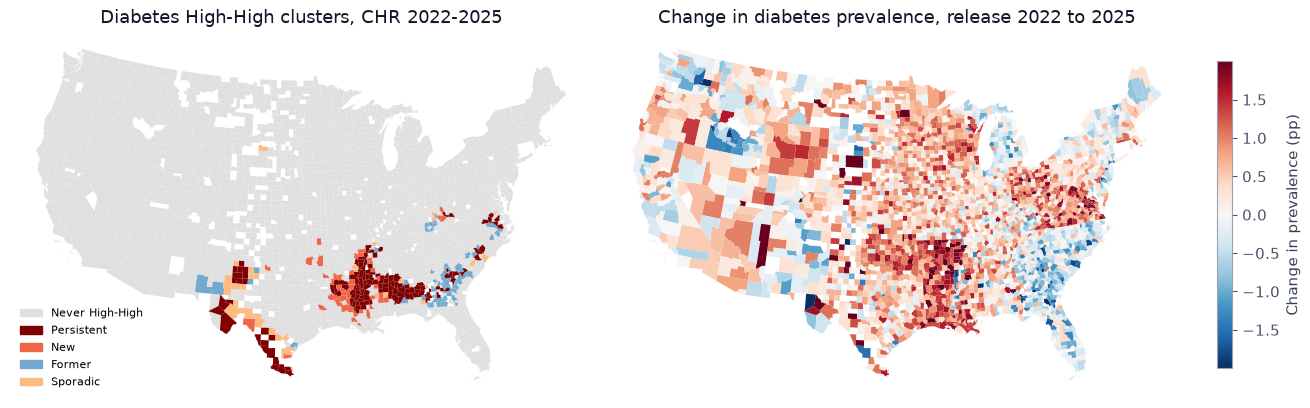

,class,n
0,Never High-High,2616
1,Persistent,138
2,New,46
3,Former,66
4,Sporadic,31


Moran's I stays between **0.670** and **0.708** across releases. Of the **281** counties that are High-High at least once, **138** (**49%**) are High-High in every release. The change between the first and last release is itself spatially clustered (Moran's I = **0.409**, p = **0.0010**), which for a model-based estimate can reflect regional revisions as much as real change.

In [20]:
hh_mat = np.column_stack([hh_by_year[t] for t in PANEL_YEARS])
n_hh = hh_mat.sum(axis=1)
first, last = hh_mat[:, 0], hh_mat[:, -1]
trend = np.full(len(counties), "Never High-High", dtype=object)
trend[n_hh > 0] = "Sporadic"
trend[first & ~last] = "Former"
trend[~first & last] = "New"
trend[n_hh == len(PANEL_YEARS)] = "Persistent"
counties["hh_trend"] = trend
counties["diab_change"] = diab_panel[:, -1] - diab_panel[:, 0]
mi_change = Moran(counties["diab_change"].to_numpy(float), w, permutations=PERM, seed=SEED)

TREND_COLORS = {
    "Never High-High": "#e0e0e0",
    "Persistent": "#7f0000",
    "New": "#ef6548",
    "Former": "#74a9cf",
    "Sporadic": "#fdbb84",
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
for label, color in TREND_COLORS.items():
    part = counties[counties["hh_trend"] == label]
    if len(part):
        part.plot(ax=axes[0], color=color, edgecolor="none", linewidth=0)
axes[0].legend(
    handles=[Patch(color=c, label=l) for l, c in TREND_COLORS.items()],
    loc="lower left", fontsize=8, frameon=False,
)
axes[0].set_title(f"Diabetes High-High clusters, CHR {PANEL_YEARS[0]}-{PANEL_YEARS[-1]}")
axes[0].set_axis_off()

lim = float(np.nanpercentile(np.abs(counties["diab_change"]), 98))
counties.plot(
    column="diab_change", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim),
    legend=True, ax=axes[1], edgecolor="none",
    legend_kwds={"shrink": 0.6, "label": "Change in prevalence (pp)"},
)
axes[1].set_title(f"Change in diabetes prevalence, release {PANEL_YEARS[0]} to {PANEL_YEARS[-1]}")
axes[1].set_axis_off()
plt.show()

trend_tbl = counties["hh_trend"].value_counts().reindex(list(TREND_COLORS), fill_value=0)
display(trend_tbl.rename_axis("class").reset_index(name="n"))
ever = int((n_hh > 0).sum())
display(Markdown(
    f"Moran's I stays between **{year_tbl['moran_I'].min():.3f}** and **{year_tbl['moran_I'].max():.3f}** across releases. "
    f"Of the **{ever}** counties that are High-High at least once, **{int(trend_tbl['Persistent'])}** "
    f"(**{trend_tbl['Persistent'] / ever * 100:.0f}%**) are High-High in every release. "
    f"The change between the first and last release is itself spatially clustered "
    f"(Moran's I = **{mi_change.I:.3f}**, p = **{mi_change.p_value:.4f}**), which for a model-based "
    f"estimate can reflect regional revisions as much as real change."
))

### Two-way fixed effects

County fixed effects remove everything that is constant within a county over the panel (including EDI and SVI, which come from one SVI release) and release fixed effects remove national shifts. What remains is whether a county's diabetes estimate moves with its own uninsured rate, child poverty, and unemployment. Standard errors are clustered by county. The pooled model without fixed effects is shown for contrast.

In [21]:
order_idx = pd.MultiIndex.from_product([counties["fips"], PANEL_YEARS], names=["fips", "year"])
P = panel.set_index(["fips", "year"]).reindex(order_idx)
fe_vars = ["uninsured", "children_poverty", "unemployment"]
FE_LABELS = {"uninsured": "% uninsured", "children_poverty": "% children in poverty", "unemployment": "% unemployed"}
n_c, n_t = len(counties), len(PANEL_YEARS)


def two_way_demean(a):
    a = a.reshape(n_c, n_t)
    return (a - a.mean(axis=1, keepdims=True) - a.mean(axis=0, keepdims=True) + a.mean()).ravel()


y_p = P["diabetes"].to_numpy(float)
X_p = P[fe_vars].to_numpy(float)
y_w = two_way_demean(y_p)
X_w = np.column_stack([two_way_demean(X_p[:, k]) for k in range(len(fe_vars))])

beta_fe, *_ = np.linalg.lstsq(X_w, y_w, rcond=None)
resid_fe = y_w - X_w @ beta_fe
bread = np.linalg.inv(X_w.T @ X_w)
Xg = X_w.reshape(n_c, n_t, -1)
ug = resid_fe.reshape(n_c, n_t)
scores = np.einsum("ctk,ct->ck", Xg, ug)
meat = scores.T @ scores
adj = (n_c / (n_c - 1)) * ((n_c * n_t - 1) / (n_c * n_t - n_c - n_t + 1 - len(fe_vars)))
se_fe = np.sqrt(np.diag(bread @ meat @ bread) * adj)
r2_within = 1 - resid_fe @ resid_fe / (y_w @ y_w)

A = np.column_stack([np.ones(len(y_p)), X_p])
beta_pool, *_ = np.linalg.lstsq(A, y_p, rcond=None)

fe_tbl = pd.DataFrame(
    {
        "pooled OLS": beta_pool[1:],
        "two-way FE": beta_fe,
        "FE cluster SE": se_fe,
        "FE z": beta_fe / se_fe,
    },
    index=[FE_LABELS[v] for v in fe_vars],
)
display(fe_tbl.style.format("{:.3f}"))

resid_rows = []
for j, yr_ in enumerate(PANEL_YEARS):
    mr = Moran(ug[:, j], w, permutations=PERM, seed=SEED)
    resid_rows.append({"CHR release": yr_, "resid_moran_I": mr.I, "p_value": mr.p_value})
resid_fe_tbl = pd.DataFrame(resid_rows).set_index("CHR release")
display(resid_fe_tbl.style.format({"resid_moran_I": "{:.3f}", "p_value": "{:.4f}"}))

within_share = float(np.var(y_w) / np.var(y_p))
display(Markdown(
    f"Only **{within_share * 100:.1f}%** of the variance in diabetes prevalence is within-county over time; "
    f"the rest is between counties. The fixed-effects coefficients are in pp of diabetes per pp of each predictor "
    f"(within R$^2$ = **{r2_within:.3f}**). The pooled coefficient on child poverty is "
    f"**{fe_tbl.loc[FE_LABELS['children_poverty'], 'pooled OLS']:.3f}** and the within-county one is "
    f"**{fe_tbl.loc[FE_LABELS['children_poverty'], 'two-way FE']:.3f}**. "
    f"Fixed-effects residuals remain spatially autocorrelated in every release "
    f"(Moran's I from **{resid_fe_tbl['resid_moran_I'].min():.3f}** to **{resid_fe_tbl['resid_moran_I'].max():.3f}**), "
    f"so a spatial panel model would be the next step."
))

,pooled OLS,two-way FE,FE cluster SE,FE z
% uninsured,0.096,0.034,0.007,5.037
% children in poverty,0.190,-0.006,0.003,-1.725
% unemployed,0.057,-0.000,0.008,-0.056


,resid_moran_I,p_value
CHR release,,
2022,0.389,0.0010
2023,0.372,0.0010
2024,0.496,0.0010
2025,0.449,0.0010


Only **3.0%** of the variance in diabetes prevalence is within-county over time; the rest is between counties. The fixed-effects coefficients are in pp of diabetes per pp of each predictor (within R$^2$ = **0.006**). The pooled coefficient on child poverty is **0.190** and the within-county one is **-0.006**. Fixed-effects residuals remain spatially autocorrelated in every release (Moran's I from **0.372** to **0.496**), so a spatial panel model would be the next step.

## Health disparity priority map

Map the descriptive HDI and list the highest-ranking counties. This is a communication layer for overlapping disadvantage, not a causal ranking.

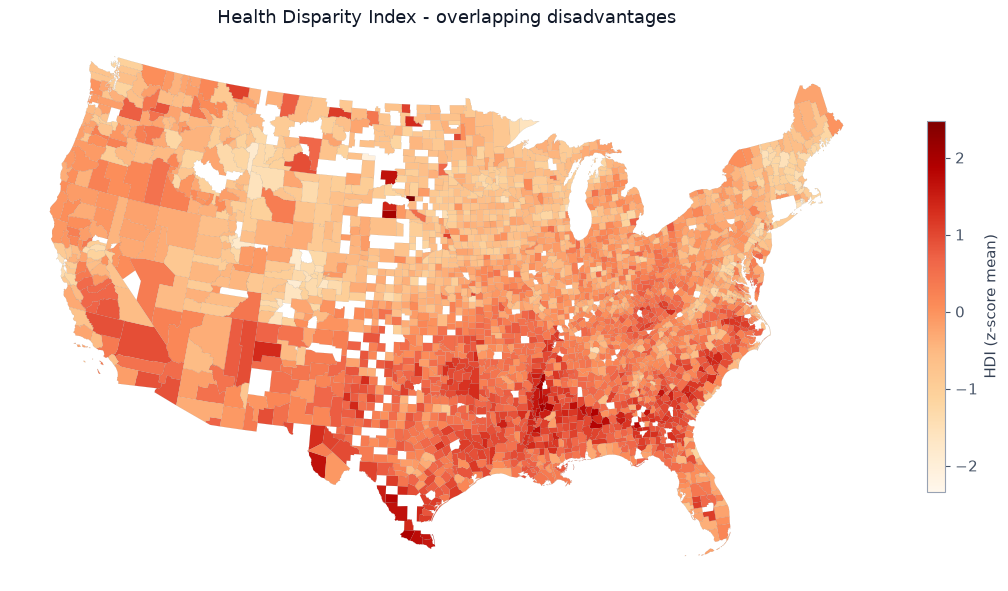

**Highest HDI counties**

,fips,COUNTY,STATE,hdi,diabetes_pct,obesity_pct,edi,svi
0,46017,Buffalo County,South Dakota,2.48,18.4,47.2,0.94,0.99
1,46121,Todd County,South Dakota,2.04,22.2,47.3,0.84,0.95
2,28053,Humphreys County,Mississippi,2.01,19.8,50.6,0.99,0.98
3,28027,Coahoma County,Mississippi,2.00,18.9,51.0,0.94,0.99
4,28143,Tunica County,Mississippi,2.00,18.1,48.6,0.94,0.96
5,28051,Holmes County,Mississippi,1.96,20.4,50.6,0.96,0.99
6,48427,Starr County,Texas,1.94,19.7,44.2,0.93,0.99
7,01105,Perry County,Alabama,1.88,19.4,52.5,0.94,0.92
8,01131,Wilcox County,Alabama,1.84,18.0,48.5,0.92,0.98
9,48127,Dimmit County,Texas,1.82,20.5,45.7,0.88,1.00


**208** FDR-adjusted HH diabetes counties; **580** in the top EDI quintile; **144** in both (geographic concentration of burden and deprivation).

In [22]:
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
counties.plot(
    column="hdi", cmap="OrRd", linewidth=0.05, edgecolor="0.4", ax=ax,
    legend=True, legend_kwds={"shrink": 0.65, "label": "HDI (z-score mean)"},
)
ax.set_title("Health Disparity Index - overlapping disadvantages")
ax.set_axis_off()
plt.show()

top = (
    counties.nlargest(15, "hdi")[
        ["fips", "COUNTY", "STATE", "hdi", "diabetes_pct", "obesity_pct", "edi", "svi"]
    ]
    .reset_index(drop=True)
)
display(Markdown("**Highest HDI counties**"))
display(top.style.format({
    "hdi": "{:.2f}", "diabetes_pct": "{:.1f}", "obesity_pct": "{:.1f}",
    "edi": "{:.2f}", "svi": "{:.2f}",
}))

# Overlap of FDR-adjusted HH diabetes and high EDI
hh = set(counties.loc[counties["lisa_diabetes_fdr"] == "HH", "fips"])
high_edi = set(counties.loc[counties["edi"] >= counties["edi"].quantile(0.8), "fips"])
overlap = hh & high_edi
display(Markdown(
    f"**{len(hh)}** FDR-adjusted HH diabetes counties; **{len(high_edi)}** in the top EDI quintile; "
    f"**{len(overlap)}** in both (geographic concentration of burden and deprivation)."
))


### How stable is the HDI ranking?

The guideline asks to test alternative weighting methods before using a composite index to rank counties. Three alternatives to the equal-weighted HDI are compared: PCA weights (first component of the eight parts), domain-balanced weights (health, socioeconomic, access, and environment each count one quarter), and a burden-only index (the three health outcomes).

,spearman_with_HDI,top_decile_retained
alternative,,
PCA weights,0.991,93%
Domain-balanced,0.981,88%
Burden only,0.913,76%


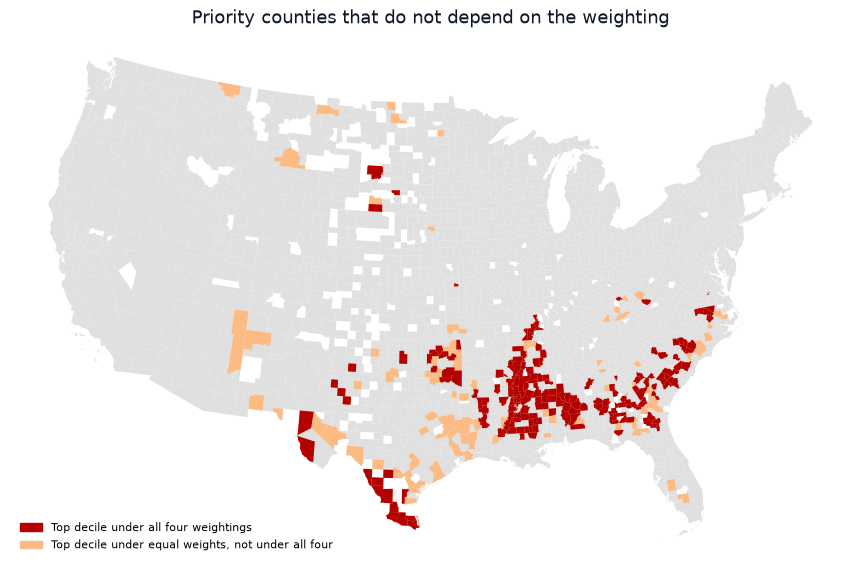

**184** of the **289** top-decile HDI counties stay in the top decile under all four weightings, led by **Mississippi** (44), **Georgia** (34), **Alabama** (17), **Texas** (16), **South Carolina** (13). The ranking is least stable against the **Burden only** index (**76%** of the top decile retained). PC1 carries **50%** of the variance of the eight parts.

In [23]:
H = hdi_parts.to_numpy(float)
_, s_h, Vt_h = np.linalg.svd(H - H.mean(axis=0), full_matrices=False)
pc_h = Vt_h[0] * np.sign(Vt_h[0].sum())
DOMAINS = {
    "health": ["z_diabetes", "z_obesity", "z_premature"],
    "socioeconomic": ["z_edi", "z_svi"],
    "access": ["z_uninsured", "z_low_pcp"],
    "environment": ["z_pm25"],
}
alt = pd.DataFrame(
    {
        "Equal weights (HDI)": counties["hdi"].to_numpy(),
        "PCA weights": H @ pc_h,
        "Domain-balanced": np.mean([hdi_parts[c].mean(axis=1) for c in DOMAINS.values()], axis=0),
        "Burden only": hdi_parts[DOMAINS["health"]].mean(axis=1).to_numpy(),
    },
    index=counties.index,
)
base = alt["Equal weights (HDI)"]
top_base = set(base.nlargest(len(base) // 10).index)
stab_rows = []
for name in alt.columns[1:]:
    top_alt = set(alt[name].nlargest(len(base) // 10).index)
    stab_rows.append({
        "alternative": name,
        "spearman_with_HDI": spearmanr(base, alt[name])[0],
        "top_decile_retained": len(top_base & top_alt) / len(top_base),
    })
stab_tbl = pd.DataFrame(stab_rows).set_index("alternative")
display(stab_tbl.style.format({"spearman_with_HDI": "{:.3f}", "top_decile_retained": "{:.0%}"}))

in_all = top_base.copy()
for name in alt.columns[1:]:
    in_all &= set(alt[name].nlargest(len(base) // 10).index)
counties["priority_robust"] = counties.index.isin(in_all)
robust_states = counties.loc[counties["priority_robust"], "STATE"].value_counts().head(5)

fig, ax = plt.subplots(figsize=(9.5, 5.6), constrained_layout=True)
counties.plot(color="#e0e0e0", edgecolor="none", ax=ax)
counties[counties.index.isin(top_base)].plot(color="#fdbb84", edgecolor="none", ax=ax)
counties[counties["priority_robust"]].plot(color="#b30000", edgecolor="none", ax=ax)
ax.legend(
    handles=[
        Patch(color="#b30000", label="Top decile under all four weightings"),
        Patch(color="#fdbb84", label="Top decile under equal weights, not under all four"),
    ],
    loc="lower left", fontsize=8, frameon=False,
)
ax.set_title("Priority counties that do not depend on the weighting")
ax.set_axis_off()
plt.show()

least = stab_tbl["top_decile_retained"].idxmin()
display(Markdown(
    f"**{len(in_all)}** of the **{len(top_base)}** top-decile HDI counties stay in the top decile under all four weightings, "
    f"led by "
    + ", ".join(f"**{s}** ({n})" for s, n in robust_states.items())
    + f". The ranking is least stable against the **{least}** index "
    f"(**{stab_tbl.loc[least, 'top_decile_retained'] * 100:.0f}%** of the top decile retained). "
    f"PC1 carries **{s_h[0] ** 2 / np.sum(s_h ** 2) * 100:.0f}%** of the variance of the eight parts."
))

## Decision log

| Decision | Choice | Why |
|---|---|---|
| Geography | CONUS counties (`US_COUNTY.shp`) | Matches Atlas county FIPS; Albers metres for weights/GWR |
| Outcomes | Diabetes, obesity, premature death | Guideline Section 15 starting point (CVD mortality proxied by YPLL) |
| Cross-section | CHR 2024 + SVI 2022 | One release per source for the main models |
| EDI | Mean of 5 SVI EPL ranks | Aligned deprivation percentiles; checked against a PCA index; not re-used as separate regressors |
| HDI | Mean of z-scored burden + deprivation + access + PM2.5 | Descriptive priority map; ranking checked under three other weightings |
| Weights | Queen + island linking | Standard for county polygons; Moran's I checked with KNN-6 |
| Local inference | LISA with FDR (9,999 permutations) for reporting; uncorrected map and analytic Gi* for comparison | Thousands of simultaneous local tests |
| Bivariate | Moran BV and FDR-adjusted bivariate LISA | Locates the EDI-diabetes association |
| Regression | OLS, SAR, SEM, SDM on standardized predictors | LM tests, LR tests, residual Moran, and Durbin impacts |
| GWR | Adaptive bisquare, k in {100,200,400} | Geographic variation in EDI slopes |
| MGWR | PySAL `mgwr`, five Deep South states | Covariate-specific bandwidths; back-fitting for all CONUS counties is slow |
| GeoAI | XGBoost + state GroupKFold + TreeSHAP | Nonlinear importance without causal claims |
| Panel | CHR releases 2022 to 2025 | Diabetes series is not comparable with the 2020 and 2021 releases |
| Panel model | Two-way fixed effects, county-clustered SE | Removes time-invariant county differences and national shifts |

### Takeaways

1. **Clustering.** Diabetes, obesity, premature death, EDI, and HDI all show strong positive Moran's I, under both Queen and KNN weights.
2. **Deprivation and disease.** EDI and diabetes are linked aspatially, through bivariate Moran's I, and locally: bivariate LISA places the high-deprivation, high-diabetes class in the South.
3. **Local structure.** About half of the uncorrected LISA clusters survive FDR adjustment, and most of the remaining High-High counties are in the upper EDI quintile.
4. **Spatial models.** SAR, SEM, and SDM reduce residual autocorrelation relative to OLS. LR tests favor the Durbin model, whose impacts separate own-county from neighboring-county associations.
5. **Spatial heterogeneity.** GWR EDI slopes are not uniform across CONUS, and MGWR shows that predictors operate at different spatial scales within the Deep South.
6. **Nonlinear importance.** TreeSHAP highlights which Atlas domains drive out-of-fold diabetes predictions under state-held-out CV.
7. **Stability over releases.** Clustering strength is stable across CHR 2022 to 2025, and about half of the counties that are ever High-High are High-High in every release. Almost all variation in diabetes prevalence is between counties, so within-county fixed-effects estimates are small and should not be read as the cross-sectional associations.
8. **Priority counties.** A core set of counties stays in the top HDI decile under every weighting tested.

### Extensions (from *Health Disparities.qmd*)

- Add CDC WONDER age-standardized CVD and all-cause mortality.
- Fit spatial panel and Bayesian spatiotemporal (CAR/BYM) models on a true annual series.
- Fit MGWR for all CONUS counties (long run) and map covariate-specific bandwidths nationally.
- Join HRSA facility counts and EPA exposures beyond CHR PM2.5.
- Publish an interactive Folium/OSM priority dashboard.

### Methodological caution

County-level spatial associations identify geographic patterns and population-level relationships. They do not establish individual-level causal relationships. Feature importance from trees is predictive attribution, not a causal effect. Direct and indirect impacts from the Durbin model are model-based associations, not estimates of spillover effects.